# RoadGuard — Executed Model Notebook and Webapp Handoff

HOG + Linear SVM baseline, four detector experiments, evaluation, error analysis, and ONNX delivery.

## Status of this notebook

The output cells were produced in the team's Google Colab session and retained from the uploaded executed notebook. The final export log records a successful 12.75 MB ONNX model, a 1,488-row test CSV, numerical conversion/channel-order checks on three validation images, and a 74.1 MiB full-results ZIP. Those binaries are separate files: saving an ipynb does not embed model weights or the dataset.

Repository cleanup added missing English explanations, corrected provenance wording, and disabled accidental detector retraining and repeated evaluation by default. **Edited code has not been run end to end after cleanup.** Where code changed, its original saved output is explicitly marked historical. Outputs are evidence from the original session, not proof that a new runtime has the variables or files. No performance numbers were changed.

## How to read or reproduce

For review, read the saved outputs; no Colab compute is needed. The existing finished session does not need to be rerun to upload this notebook. For a new runtime, install dependencies and execute sections 1–10 to download and audit data, extract HOG features, and train the inexpensive SVM baseline. The public dataset link is read from the pinned Git source and downloaded directly to temporary runtime disk; no personal Drive copy, Drive mounting, or Roboflow API key is required.

Default `RUN_TRAINING=False`: restore the four trusted run backups in section 10a. A fresh runtime needs these checkpoint files separately; use the original four run ZIPs, or extract the per-run folders from the full `RoadGuard_Model_Results.zip` into `ROOT/runs` (its `models/<run>` folders include best.pt/last.pt and training results; section 10a expects these weights under each run's `weights/` subfolder). Do not assume the ipynb can reconstruct weights without training. Unavailable training metadata remains unavailable rather than invented.

If rebuilding missing validation/test results, explicitly enable the corresponding evaluation flags in section 2 after restoring all four experiments. These results reproduce the already-exposed test set; they are not fresh independent evaluation. Sections 13–23 then analyze and export the frozen experiments. Training cells 10b/10c and 11/12 are retained for traceability and skip with the default flag. Do not start another trial simply to complete the handoff. Any future model development needs a fresh held-out evaluation protocol.

## Dataset and provenance

- Repository: https://github.com/shaisadeh/Final-Project-DS ; reviewed source commit `05b9d4f4fac4c5fb2c53fb0a6e443bb5412e7bfe`.
- Source files: `CHARTER_RoadGuard.md`, `Data/DataSetFinalLink.md`, `Data/DataProcces_Eda.ipynb`.
- Upstream project: https://universe.roboflow.com/xjsj/road-damage-10k/dataset/1 ; the source listing identifies CC BY 4.0. Retain attribution and verify redistribution rights for derived data/weights separately.
- The archive is the team's processed dataset. The charter/EDA use inconsistent RDD2020/RDD2022 names, so this notebook does not assert a canonical RDD release identity.
- Archive SHA256: `9551c4a5d43cdd9a100796d58476c7245e635174be57870e10439104c7bab84c`.
- Split sizes: 14,346 train / 1,265 validation / 1,488 test images. Generic processed YAML names are not semantic evidence. The original Roboflow YAML and repository preprocessing that preserves numeric IDs establish the native order below.
- Exact hash/name checks do not establish sequence independence. Country origin is unavailable; country-level evaluation was skipped. Independent local field evaluation was not run (N=0).

## Two distinct class-ID contracts

| ID | Native dataset and PyTorch checkpoints | Delivered ONNX for the webapp |
|---|---|---|
| 0 | D20 — Alligator cracks | D00 — Longitudinal cracks |
| 1 | D00 — Longitudinal cracks | D10 — Transverse cracks |
| 2 | D40 — Potholes | D20 — Alligator cracks |
| 3 | D10 — Transverse cracks | D40 — Potholes |

Section 22b reorders actual ONNX class-score channels and its metadata. It does not relabel the dataset or native checkpoints. Do not change `NAMES` to the webapp order and do not apply a second permutation in the browser. Older training figures may retain incorrect semantic names; numeric IDs and the corrected reports are the reference. Earlier printed mapping-status wording ('Data Lead confirmed') is historical; verified provenance is the original source YAML plus ID-preserving preprocessing. Section 22 now writes that provenance directly.

## Results and interpretation

HOG + SVM selected C=0.001 on validation: training macro-F1=0.8080, validation=0.6833. Test crop accuracy=0.681315 and macro-F1=0.691029. Crops use known annotation locations; these are not end-to-end detection scores. Historical classification-report displays broadcast the scalar accuracy into the support column; 0.679 in that row is an accuracy value, not an object count. The revised display separates accuracy.

| Detector | Test mAP50 | D40 precision | D40 recall | Frozen confidence |
|---|---:|---:|---:|---:|
| YOLOv5u nano | 0.351480 | 0.392022 | 0.422222 | 0.15 |
| YOLOv8n original | 0.360195 | 0.405556 | 0.432593 | 0.15 |
| YOLOv8n lower LR | 0.386980 | 0.445826 | 0.371852 | 0.25 |
| YOLOv8n lower LR + color augmentation | 0.377837 | 0.043762 | 0.794074 | 0.01 |

The original validation rule selected the color-augmentation experiment; it was not selected using test results. Its D40 test counts were 536 TP / 11,712 FP / 139 FN. **Neither the 0.80 D40 recall target nor the 0.55 mAP50 target was met.** The very low confidence threshold has a substantial false-alarm burden. No production-readiness claim is made. A crop diagnostic favored SVM; YOLO was trained on full images, so that diagnostic alone does not choose an end-to-end detector.

## Delivery and remaining work

The webapp handoff contains `webapp/assets/models/yolov8n-roadguard.onnx`, `data/batch_eval/yolo_predictions.csv`, `handoff_contract.json` and `README_HANDOFF.md`. ONNX uses static float32 RGB NCHW 640x640 input, aspect-preserving letterbox padding, raw box/class outputs and external class-aware NMS. See section 22b for exact settings.

The CSV has one highest-confidence retained detection per test image; bbox uses colon-separated original-image xyxy pixels. One image has no detection: its class/bbox fields are blank and confidence is 0.0. This is missing visual evidence, not a safe-road class. Top1-only rows cannot reproduce full detection mAP or pothole recall. The three-image conversion check passed, but browser integration and a full ONNX test evaluation have not been performed.

The CV interface returns findings for human review. It does not implement RAG, operational severity, dispatch or an autonomous agent. Field testing and the teammate's held-out agent evaluation remain pending. Connecting an agent does not remove the CV limitations. Relative box area is not physical area/depth/severity, and model scores are not calibrated probabilities.


## 1 · Install dependencies

This cell installs the detector library at a fixed version, `gdown` for downloading the public source file, and the image-processing and evaluation tools. `%pip` installs into the notebook's Python environment. The existing Colab PyTorch installation is retained to preserve CUDA compatibility. The next cell prints actual versions and checks GPU availability. If Colab requests a restart after installation, restart and continue from cell 2. Installing packages does not train a model or connect to your personal Drive.


In [2]:
%pip -q install "ultralytics==8.4.184" "gdown==5.2.0" scikit-image scikit-learn pandas matplotlib seaborn pyyaml pillow tqdm joblib


## 2 · Environment, random seed, and experiment settings

This cell imports the libraries, sets the random seed to 42, and creates local runtime directories. `DEVICE` should identify a GPU before full training. In Colab, select Runtime → Change runtime type → T4 GPU. A CPU can run initial checks but is too slow for practical full training.

`EPOCHS=30`, `BATCH=8`, and `IMGSZ=640` are starting settings for a T4. If memory is insufficient, reduce BATCH before starting the experiments and record the change. Both detectors receive the same training budget. Seeds reduce variation but do not guarantee identical results across hardware or CUDA versions. Matching, NMS, and quality parameters are declared in advance; the operating confidence threshold is selected later using validation data only.

`CLASS_MAPPING_CONFIRMED` must remain False until the Data Lead verifies the index-to-damage mapping against the original annotation specification. `FIELD_ROOT` is the optional local field-test directory. Package versions are saved with the outputs.

Completion defaults: RUN_TRAINING=False; validation and test recomputation are also disabled. Existing in-memory results are reused. If rebuilding after a reset, explicitly enable only the evaluation flags needed after restoring the four runs. Do not tune further on the exposed test set.


**Output provenance:** The saved output below is retained from the original Colab execution. The code in this cell was subsequently edited for the repository and has not been rerun. Default replay guards may now skip work that the historical output records. No numeric result has been recalculated or changed.

In [ ]:
from pathlib import Path
from collections import Counter, defaultdict
import os, sys, re, json, random, hashlib, shutil, zipfile, subprocess, time, platform, importlib.metadata
import numpy as np
import pandas as pd
import yaml, torch, cv2, joblib
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageDraw
from tqdm.auto import tqdm
from IPython.display import display
from ultralytics import YOLO
from skimage.feature import hog
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score

RUN_TRAINING = False  # Completed experiments are reused; no new trials.
ALLOW_VALIDATION_EVALUATION = False  # Enable only when rebuilding missing results.
ALLOW_TEST_EVALUATION = False  # Reproduction only; never tune on these results.
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
ROOT = Path('/content/roadguard') if Path('/content').exists() else Path.cwd() / 'roadguard'
ROOT.mkdir(parents=True, exist_ok=True)
OUT = ROOT / 'outputs'; OUT.mkdir(exist_ok=True)
RUNS = ROOT / 'runs'; RUNS.mkdir(exist_ok=True)
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
IMGSZ, BATCH, EPOCHS, PATIENCE = 640, 8, 30, 10
MATCH_IOU, NMS_IOU = 0.50, 0.70
RECALL_TARGET, MAP50_TARGET = 0.80, 0.55
PRED_FLOOR = 0.001
THRESHOLDS = [0.01, 0.025, 0.05, 0.10, 0.15, 0.20, 0.25, 0.35, 0.50, 0.65, 0.80]
REPO_URL = 'https://github.com/shaisadeh/Final-Project-DS.git'
REPO_COMMIT = '05b9d4f4fac4c5fb2c53fb0a6e443bb5412e7bfe'
# Evidence: user-supplied original Roboflow YAML and ID-preserving repository preprocessing.
CLASS_MAPPING_CONFIRMED = True
# Numeric IDs in the processed archive; do not infer their order from generic Class_0 names.
DECLARED_MAPPING = {0: "D20", 1: "D00", 2: "D40", 3: "D10"}
FIELD_ROOT = ROOT / 'field'  # optional: images/ and labels/; independent local images
versions = {p: importlib.metadata.version(p) for p in
            ['ultralytics','gdown','numpy','pandas','torch','scikit-learn','scikit-image']}
print('Python:', platform.python_version(), '\nVersions:', versions)
print('Device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 0 else 'CPU: enable a GPU before training')
print('Temporary workspace:', ROOT)
(OUT / 'versions.json').write_text(json.dumps(versions, indent=2))


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Python: 3.13.16 
Versions: {'ultralytics': '8.4.184', 'gdown': '5.2.0', 'numpy': '2.1.3', 'pandas': '2.2.3', 'torch': '2.11.0+cu130', 'scikit-learn': '1.6.1', 'scikit-image': '0.25.2'}
Device: 0 Tesla T4
Temporary workspace: /content/roadguard


173

## 3 · Read the charter and dataset link from Git

This cell clones the repository and checks out the exact commit used to prepare the notebook. Pinning the commit prevents future repository edits from silently changing an experiment. It then reads the charter and extracts the public Drive URL from `Data/DataSetFinalLink.md`, rather than using the raw-data link or a personal path.

At preparation time, the processed-data URL referred to file `1xzHdXoXc4NPibka0KG9GAqq_EfdTUulo`. The cell displays the source and saves the source documents with the results. To adopt a future repository revision, deliberately update REPO_COMMIT and recheck the data layout, class mapping, and provenance.


In [4]:
REPO = ROOT / 'source_repo'
if not (REPO / '.git').exists():
    subprocess.run(['git', 'clone', REPO_URL, str(REPO)], check=True)
subprocess.run(['git', '-C', str(REPO), 'fetch', 'origin', REPO_COMMIT], check=True)
subprocess.run(['git', '-C', str(REPO), 'checkout', '--detach', REPO_COMMIT], check=True)
charter_text = (REPO / 'CHARTER_RoadGuard.md').read_text()
link_text = (REPO / 'Data/DataSetFinalLink.md').read_text()
urls = re.findall(r'https://drive\.google\.com/[^\s<>]+', link_text)
if len(urls) != 1: raise ValueError('Expected exactly one processed-dataset link in Git.')
DATA_URL = urls[0].strip()
print('Git commit:', REPO_COMMIT, '\nProcessed dataset:', DATA_URL)
print(charter_text)
(OUT / 'CHARTER_RoadGuard.md').write_text(charter_text)
(OUT / 'DataSetFinalLink.md').write_text(link_text)


Git commit: 05b9d4f4fac4c5fb2c53fb0a6e443bb5412e7bfe 
Processed dataset: https://drive.google.com/file/d/1xzHdXoXc4NPibka0KG9GAqq_EfdTUulo/view?usp=sharing
# **RoadGuard Project Charter**

**AI-Powered Road Hazard Detection and Prioritization System**  
Team members: Benny Saliroses, Ovad Biton, Or Arbeli, Shai Sadeh

# **1  Problem and User**

A municipal infrastructure control-center manager or public works manager receives road-hazard reports and photographs of inconsistent quality and must quickly determine the hazard type and whether it requires urgent inspection, scheduling in the maintenance plan, or additional evidence. Uniform manual triage delays important cases and may dispatch crews to false alarms. RoadGuard will analyze an image, detect cracks and potholes, and recommend a justified next action. It is a decision-support system only: it will not determine engineering fitness or close a road without approval from an authorized professional.  
The long-term operational objec

83

## 4 · Download directly to temporary storage and extract safely

`gdown` downloads the public ZIP directly into the runtime. It does not mount Drive or create a dataset copy in the runner's personal Drive. A free-space check precedes the download; another check uses the archive's uncompressed size before extraction. Partial downloads use a `.part` suffix and must be recognized as ZIP files before becoming the final archive.

The SHA256 hash records the exact downloaded archive. It is a reproducibility identifier, not verification against an official published checksum. Extraction rejects paths outside the destination directory and symbolic links. A completion marker prevents repeated extraction. An incomplete notebook-owned extraction directory may be removed and recreated. If public sharing or Google download quotas prevent downloading, correct access to the team's source file; a personal Drive copy is not required.


In [5]:
import gdown
ARCHIVE = ROOT / 'processed_dataset.zip'
EXTRACT = ROOT / 'dataset_extracted'
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024*1024), b''): h.update(chunk)
    return h.hexdigest()
if not ARCHIVE.exists():
    if shutil.disk_usage(ROOT).free < 5 * 1024**3:
        raise RuntimeError('Need at least 5 GiB free before downloading; more for extraction/training.')
    partial = ARCHIVE.with_suffix('.part')
    try:
        gdown.download(url=DATA_URL, output=str(partial), fuzzy=True, quiet=False)
        if not zipfile.is_zipfile(partial): raise ValueError('Downloaded content is not a ZIP.')
        partial.replace(ARCHIVE)
    except Exception as e:
        raise RuntimeError('Dataset download failed. Verify public sharing and Google download quota.') from e
ARCHIVE_SHA256 = sha256_file(ARCHIVE)
marker = EXTRACT / '.extracted_sha256'
if marker.exists() and marker.read_text() != ARCHIVE_SHA256:
    raise RuntimeError('Archive changed: use a fresh extraction directory before continuing.')
if not marker.exists():
    if EXTRACT.exists(): shutil.rmtree(EXTRACT)  # only this notebook-owned, incomplete extraction
    EXTRACT.mkdir()
    with zipfile.ZipFile(ARCHIVE) as z:
        needed = sum(x.file_size for x in z.infolist())
        if shutil.disk_usage(ROOT).free < needed + 3 * 1024**3:
            raise RuntimeError(f'Need {needed/1024**3:.1f} GiB for extraction plus 3 GiB reserve.')
        for item in z.infolist():
            target = (EXTRACT / item.filename).resolve()
            if not target.is_relative_to(EXTRACT.resolve()): raise ValueError('Unsafe ZIP path')
            if ((item.external_attr >> 16) & 0o170000) == 0o120000: raise ValueError('ZIP symlink refused')
        z.extractall(EXTRACT)
    marker.write_text(ARCHIVE_SHA256)
provenance = {'repo_url':REPO_URL, 'commit':REPO_COMMIT, 'dataset_url':DATA_URL,
              'archive_sha256':ARCHIVE_SHA256, 'dataset_release':'unverified: charter RDD2022 / EDA RDD2020'}
(OUT / 'data_provenance.json').write_text(json.dumps(provenance, indent=2))
print('Archive GiB:', round(ARCHIVE.stat().st_size/1024**3, 2), '\nSHA256:', ARCHIVE_SHA256)


Downloading...
From (original): https://drive.google.com/uc?id=1xzHdXoXc4NPibka0KG9GAqq_EfdTUulo
From (redirected): https://drive.google.com/uc?id=1xzHdXoXc4NPibka0KG9GAqq_EfdTUulo&confirm=t&uuid=e6644563-cbd3-4b62-8100-a4287f32cbfa
To: /content/roadguard/processed_dataset.part
100%|██████████| 1.54G/1.54G [00:25<00:00, 61.3MB/s]


Archive GiB: 1.44 
SHA256: 9551c4a5d43cdd9a100796d58476c7245e635174be57870e10439104c7bab84c


## 5 · Discover the dataset layout and generate a runtime YAML

This cell locates a single dataset root containing train, val or valid, and test, each with images and labels directories. It preserves the data team's split instead of making a new random split. A new YAML contains absolute paths valid in this runtime, replacing stale paths from the prepared archive.

Class names are read from the source YAML. If it contains only generic names such as Class_0, the notebook uses the D00–D40 mapping declared in the repository EDA but marks it provisional. **Do not infer index meanings by guesswork.** The Data Lead must verify them against the original source before setting CLASS_MAPPING_CONFIRMED. Without confirmation, metrics may be calculated under the declared mapping, but the notebook will not claim that the semantic D40 target has been verified. An explicit semantic mapping that contradicts the declaration stops execution.


**Output provenance:** The saved output below is retained from the original Colab execution. The code in this cell was subsequently edited for the repository and has not been rerun. Default replay guards may now skip work that the historical output records. No numeric result has been recalculated or changed.

In [ ]:
candidates = []
for train_dir in EXTRACT.rglob('train'):
    root = train_dir.parent
    val_name = 'val' if (root/'val/images').is_dir() else 'valid'
    if all((root/s/t).is_dir() for s in ['train',val_name,'test'] for t in ['images','labels']):
        candidates.append((root,val_name))
if len(candidates) != 1: raise RuntimeError(f'Expected one YOLO dataset root; found {candidates}')
DATA_ROOT, VAL_NAME = candidates[0]
SPLIT_DIRS = {'train': DATA_ROOT/'train', 'val': DATA_ROOT/VAL_NAME, 'test': DATA_ROOT/'test'}
yaml_candidates = [p for p in DATA_ROOT.glob('*.y*ml') if p.is_file()]
source_configs = [(p,yaml.safe_load(p.read_text())) for p in yaml_candidates]
source_configs = [(p,c) for p,c in source_configs if isinstance(c,dict) and 'names' in c]
if len(source_configs) != 1: raise RuntimeError('Need one source YAML with class names; inspect archive.')
SOURCE_YAML, original_config = source_configs[0]
raw = original_config['names']
ORIGINAL_NAMES = dict(enumerate(raw)) if isinstance(raw,list) else {int(k):str(v) for k,v in raw.items()}
if set(ORIGINAL_NAMES) != set(DECLARED_MAPPING): raise ValueError(f'Unexpected class IDs: {ORIGINAL_NAMES}')
semantic = {i:str(n).upper() for i,n in ORIGINAL_NAMES.items()}
if set(semantic.values()) == set(DECLARED_MAPPING.values()):
    if semantic != DECLARED_MAPPING: raise ValueError('Source YAML contradicts declared class mapping.')
    MAPPING_STATUS = 'semantic codes present in source YAML'
    MAPPING_VERIFIED = True
else:
    MAPPING_VERIFIED = CLASS_MAPPING_CONFIRMED
    MAPPING_STATUS = 'Original Roboflow YAML supplied by user; repository preprocessing preserves numeric IDs' if MAPPING_VERIFIED else 'PROVISIONAL: repository EDA declaration only'
NAMES = DECLARED_MAPPING.copy()
POTHOLE_ID = next(i for i,n in NAMES.items() if n=='D40')
DATA_YAML = ROOT/'data_runtime.yaml'
runtime_config = {'path':str(DATA_ROOT.resolve()),
                  **{s:str((p/'images').resolve()) for s,p in SPLIT_DIRS.items()}, 'names':NAMES}
DATA_YAML.write_text(yaml.safe_dump(runtime_config, sort_keys=False))
(OUT/'data_runtime.yaml').write_text(DATA_YAML.read_text())
(OUT/'class_mapping.json').write_text(json.dumps({'original':ORIGINAL_NAMES,'used':NAMES,
                                               'status':MAPPING_STATUS,'verified':MAPPING_VERIFIED},indent=2))
print('Dataset root:', DATA_ROOT, '\nSource names:', ORIGINAL_NAMES, '\nMapping:',NAMES, MAPPING_STATUS)


Dataset root: /content/roadguard/dataset_extracted/road_damage_detect 
Source names: {0: 'Class_0', 1: 'Class_1', 2: 'Class_2', 3: 'Class_3'} 
Mapping: {0: 'D20', 1: 'D00', 2: 'D40', 3: 'D10'} Data Lead confirmed


## 6 · Audit images, annotations, and cross-split leakage

Each annotation line must have the YOLO format `class x_center y_center width height`, with normalized coordinates. The audit checks column count, finite values, valid integer class IDs, positive dimensions, and box boundaries. Every image is decoded. Missing labels and labels without corresponding images are failures; an empty label file may represent a valid background image and is reported separately.

The audit rejects identical files, identical decoded pixels, and normalized original-image names that cross splits. Normalization removes Roboflow hashes and recognized augmentation suffixes. Recognized augmented images in validation or test stop execution. Country is inferred only from supported filename prefixes; otherwise it remains unknown. The audit report and manifest are saved, and failures block training.

**Limitation:** original-name normalization does not identify actual camera sequences. Hash checks do not rule out neighboring frames or near-duplicates. Without original sequence metadata, this notebook cannot establish zero sequence-level leakage.


In [7]:
EXTS = {'.jpg','.jpeg','.png','.bmp','.webp'}
def original_key(stem):
    stem = re.sub(r'_aug(?:_?\d+)?$', '', stem, flags=re.I)
    stem = stem.split('.rf.')[0]
    return re.sub(r'_(jpg|jpeg|png)$','',stem,flags=re.I)
def country_from_name(name):
    key = original_key(Path(name).stem).lower()
    patterns = {'Japan':r'^(japan|jp)[_-]', 'India':r'^(india|in)[_-]',
                'Czech':r'^(czech|cz)[_-]', 'Norway':r'^(norway|no)[_-]',
                'United_States':r'^(united_states|usa|us)[_-]', 'China':r'^(china|cn)[_-]'}
    return next((country for country,pat in patterns.items() if re.search(pat,key)), 'unknown')
def read_yolo(path):
    rows=[]
    for line_no,line in enumerate(Path(path).read_text().splitlines(),1):
        if not line.strip(): continue
        a=np.asarray([float(v) for v in line.split()], dtype=float)
        if a.shape!=(5,) or not np.isfinite(a).all(): raise ValueError(f'{path}:{line_no}: malformed')
        cid,x,y,w,h=a
        if cid!=int(cid) or int(cid) not in NAMES: raise ValueError(f'{path}:{line_no}: class')
        if w<=0 or h<=0 or not (0<=x<=1 and 0<=y<=1 and w<=1 and h<=1):
            raise ValueError(f'{path}:{line_no}: invalid normalized box')
        if min(x-w/2,y-h/2)<-1e-4 or max(x+w/2,y+h/2)>1.0001:
            raise ValueError(f'{path}:{line_no}: box extends outside image')
        rows.append(a)
    return np.asarray(rows,dtype=float).reshape(-1,5)
records=[]; errors=[]; labels_by_path={}
for split,folder in SPLIT_DIRS.items():
    images=sorted(p for p in (folder/'images').iterdir() if p.suffix.lower() in EXTS)
    if not images: raise ValueError(f'No images in {split}')
    stems=[p.stem for p in images]
    if len(stems)!=len(set(stems)): errors.append(f'{split}: duplicate image stems')
    orphans={p.stem for p in (folder/'labels').glob('*.txt')}-set(stems)
    if orphans: errors.append(f'{split}: orphan labels: {len(orphans)}')
    for p in tqdm(images,desc=f'Audit {split}'):
        try:
            lab=folder/'labels'/f'{p.stem}.txt'
            if not lab.exists(): raise ValueError('missing label')
            a=read_yolo(lab); labels_by_path[str(p)]=a
            with Image.open(p) as im:
                rgb=np.asarray(im.convert('RGB')); height,width=rgb.shape[:2]
            pixel_hash=hashlib.sha256(str(rgb.shape).encode()+rgb.tobytes()).hexdigest()
            aug=bool(re.search(r'_aug(?:_?\d+)?$',p.stem,re.I))
            if split!='train' and aug: raise ValueError('augmented image in evaluation split')
            records.append({'split':split,'path':str(p),'label':str(lab),'stem':p.stem,
                'group':original_key(p.stem),'country':country_from_name(p.name),
                'augmented':aug,'width':width,'height':height,'objects':len(a),
                'sha256':sha256_file(p),'pixel_hash':pixel_hash})
        except Exception as e: errors.append(f'{p}: {e}')
manifest=pd.DataFrame(records)
for key in ['group','sha256','pixel_hash']:
    leaking=manifest.groupby(key)['split'].nunique()
    if (leaking>1).any(): errors.append(f'{key}: {(leaking>1).sum()} overlaps across splits')
manifest.to_csv(OUT/'data_manifest.csv',index=False)
(OUT/'audit.json').write_text(json.dumps({'errors':errors,'sequence_leakage_verified':False,
    'note':'No original sequence IDs; file/pixel/original-name checks only.'},indent=2))
if errors: raise RuntimeError('Audit failed; fix upstream data, then rerun:\n'+'\n'.join(errors[:30]))
print(manifest.groupby('split').agg(images=('path','size'),objects=('objects','sum'),
                                    empty_labels=('objects',lambda x:int((x==0).sum()))))
print(pd.crosstab(manifest.split,manifest.country))


Audit train:   0%|          | 0/14346 [00:00<?, ?it/s]

Audit val:   0%|          | 0/1265 [00:00<?, ?it/s]

Audit test:   0%|          | 0/1488 [00:00<?, ?it/s]

       images  objects  empty_labels
split                               
test     1488     3072             0
train   14346    29278             0
val      1265     2666             0
country  unknown
split           
test        1488
train      14346
val         1265


## 7 · Inspect class distribution and annotation examples

The table and bar chart count annotated objects rather than images, because an image can contain several defects. They compare train, validation, and test, including offline-augmented training examples.

Six training images are sampled with a fixed seed and displayed with ground-truth boxes. Check coordinate conversion, box placement, and whether the declared classes visually match the examples. Visual inspection does not establish an official class mapping or validate every annotation. Test counts are used here only for structural auditing, not model or threshold selection. The table and figures are saved.


split,test,train,val
class,,,
D20,1041,9782,871
D00,805,7693,753
D40,675,6674,561
D10,551,5129,481


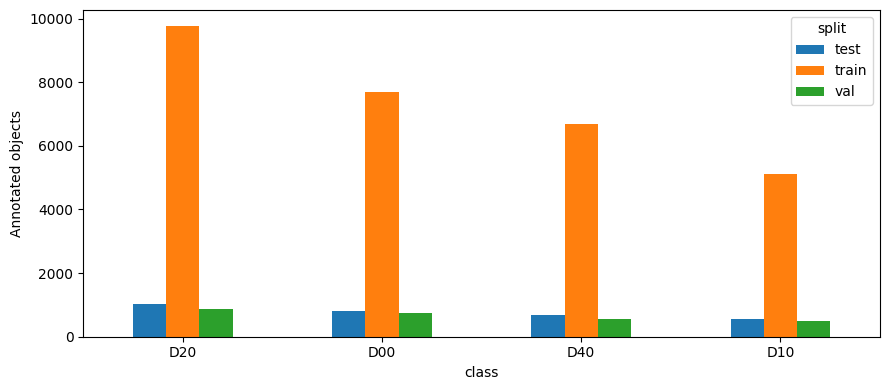

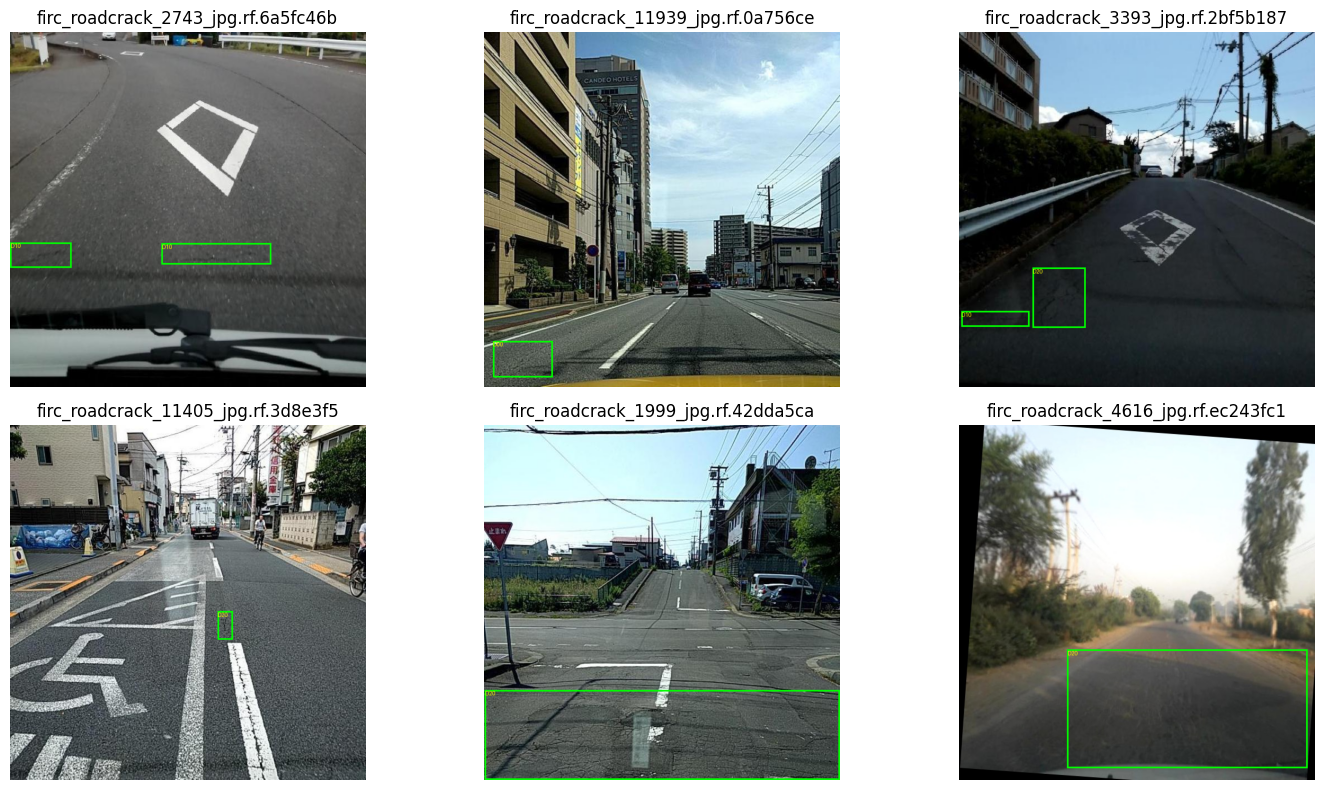

In [11]:
class_rows=[]
for r in manifest.itertuples():
    for a in labels_by_path[r.path]: class_rows.append({'split':r.split,'class':NAMES[int(a[0])]})
class_counts=pd.crosstab(pd.DataFrame(class_rows)['class'],pd.DataFrame(class_rows)['split']).reindex(NAMES.values(),fill_value=0)
display(class_counts)
class_counts.to_csv(OUT/'class_counts.csv')
class_counts.plot.bar(figsize=(9,4)); plt.ylabel('Annotated objects'); plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(OUT/'class_distribution.png'); plt.show()
def gt_xyxy(path):
    a=labels_by_path[str(path)]
    r=manifest.loc[manifest.path==str(path)].iloc[0]
    if not len(a): return np.empty((0,5))
    x,y,w,h=a[:,1:].T
    return np.column_stack([a[:,0],(x-w/2)*r.width,(y-h/2)*r.height,(x+w/2)*r.width,(y+h/2)*r.height])
def draw_boxes(path,boxes,pred=False):
    im=Image.open(path).convert('RGB'); draw=ImageDraw.Draw(im)
    for b in boxes:
        cid,x1,y1,x2,y2= b[:5]
        text=NAMES[int(cid)]+(f' {b[5]:.2f}' if pred else '')
        draw.rectangle([x1,y1,x2,y2],outline='red' if pred else 'lime',width=3)
        draw.text((max(0,x1),max(0,y1)),text,fill='yellow')
    return im
sample=manifest.query("split=='train'").sample(min(6,(manifest.split=='train').sum()),random_state=SEED)
fig,axes=plt.subplots(2,3,figsize=(15,8))
for ax,(_,r) in zip(axes.flat,sample.iterrows()):
    ax.imshow(draw_boxes(r.path,gt_xyxy(r.path))); ax.set_title(Path(r.path).name[:35]); ax.axis('off')
for ax in axes.flat[len(sample):]: ax.axis('off')
plt.tight_layout(); plt.savefig(OUT/'annotation_examples.png'); plt.show()


## 8 · Extract HOG features for the traditional baseline

As required by the charter, this baseline classifies annotated damage regions. Each ground-truth box is cropped, resized to 64×64 grayscale, and represented by Histogram of Oriented Gradients features. HOG describes local edge orientations without a CNN.

To limit processing time, the training sample contains at most 1,500 boxes per class from original training images only, sampled with a fixed seed. All annotated validation and test crops are retained. **This is crop classification, not object detection:** the baseline receives the correct location, has no background class, and does not receive detection mAP. A later diagnostic compares the detectors on these same known crops; full-image detection metrics are reported separately.


In [19]:
HOG_CAP_PER_CLASS=1500
HOG_CROP_SIZE=(64,64)
def crop_features(path,a):
    with Image.open(path) as im:
        im=im.convert('RGB'); W,H=im.size
        _,x,y,w,h=a
        box=(max(0,int(np.floor((x-w/2)*W))),max(0,int(np.floor((y-h/2)*H))),
             min(W,int(np.ceil((x+w/2)*W))),min(H,int(np.ceil((y+h/2)*H))))
        if box[2]<=box[0] or box[3]<=box[1]: raise ValueError('Degenerate crop')
        crop=im.crop(box).resize(HOG_CROP_SIZE).convert('L')
    return hog(np.asarray(crop),orientations=9,pixels_per_cell=(8,8),cells_per_block=(2,2),block_norm='L2-Hys')
crop_indices={}
for split in ['train','val','test']:
    pool=defaultdict(list)
    for r in manifest.loc[manifest.split==split].itertuples():
        if split=='train' and r.augmented: continue
        for j,a in enumerate(labels_by_path[r.path]): pool[int(a[0])].append((r.path,j))
    rng=random.Random(SEED)
    crop_indices[split]=[]
    for cid,pairs in sorted(pool.items()):
        if split=='train': pairs=rng.sample(pairs,min(len(pairs),HOG_CAP_PER_CLASS))
        crop_indices[split].extend(pairs)
HOG_DATA={}
for split,pairs in crop_indices.items():
    feats=[]; targets=[]
    for path,j in tqdm(pairs,desc=f'HOG {split}'):
        a=labels_by_path[path][j]; feats.append(crop_features(path,a)); targets.append(int(a[0]))
    HOG_DATA[split]=(np.asarray(feats,dtype=np.float32),np.asarray(targets))
    print(split,HOG_DATA[split][0].shape,Counter(targets))


HOG train:   0%|          | 0/6000 [00:00<?, ?it/s]

train (6000, 1764) Counter({0: 1500, 1: 1500, 2: 1500, 3: 1500})


HOG val:   0%|          | 0/2666 [00:00<?, ?it/s]

val (2666, 1764) Counter({0: 871, 1: 753, 2: 561, 3: 481})


HOG test:   0%|          | 0/3072 [00:00<?, ?it/s]

test (3072, 1764) Counter({0: 1041, 1: 805, 2: 675, 3: 551})


## 9 · Train HOG + Linear SVM and select C on validation

This cell trains five HOG + Linear SVM candidates with different C values. StandardScaler is fitted on training data only. Each candidate is evaluated on both training and validation using Macro-F1. The training–validation gap helps identify possible overfitting, but does not establish it on its own.

The model is selected by validation Macro-F1 only, with smaller C preferred in an exact tie. A score plot, per-class validation report, and confusion matrix support error analysis. The selected pipeline and reports are saved under the filenames expected by later cells. Test data is not used.

The plot compares regularization settings, not training epochs. If a convergence warning appears, convergence should be checked before interpreting the comparison.


**Output provenance:** The saved output below is retained from the original Colab execution. The code in this cell was subsequently edited for the repository and has not been rerun. Default replay guards may now skip work that the historical output records. No numeric result has been recalculated or changed.

Training SVM with C=0.001...
Done | Train F1: 0.808 | Validation F1: 0.683 | Gap: 0.125 | Time: 12.5s
Training SVM with C=0.003...
Done | Train F1: 0.837 | Validation F1: 0.675 | Gap: 0.162 | Time: 15.9s
Training SVM with C=0.01...
Done | Train F1: 0.874 | Validation F1: 0.655 | Gap: 0.219 | Time: 21.3s
Training SVM with C=0.1...
Done | Train F1: 0.933 | Validation F1: 0.619 | Gap: 0.315 | Time: 41.9s
Training SVM with C=1.0...
Done | Train F1: 0.975 | Validation F1: 0.591 | Gap: 0.384 | Time: 212.4s

Training and validation comparison:


,C,train_macro_f1,val_macro_f1,train_val_gap,seconds
0,0.001,0.8080,0.6833,0.1247,12.4968
1,0.003,0.8370,0.6751,0.1619,15.8668
2,0.010,0.8735,0.6549,0.2186,21.2741
3,0.100,0.9333,0.6187,0.3147,41.9333
4,1.000,0.9746,0.5910,0.3836,212.3895


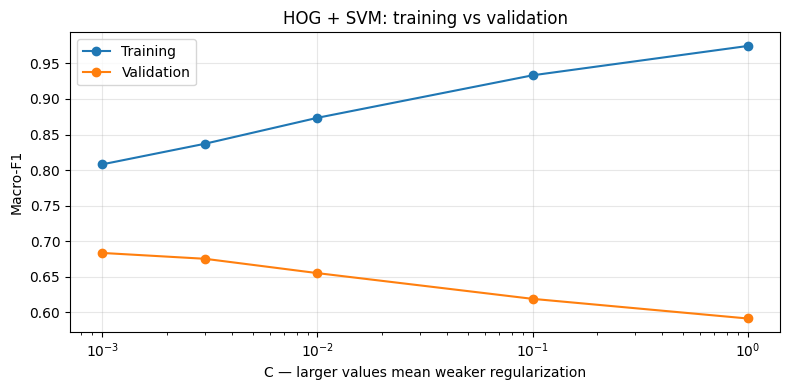


Selected model — validation classification report:


,precision,recall,f1-score,support
D20,0.700,0.605,0.649,871.000
D00,0.672,0.707,0.689,753.000
D40,0.585,0.586,0.586,561.000
D10,0.753,0.875,0.810,481.000
accuracy,0.679,0.679,0.679,0.679
macro avg,0.678,0.693,0.683,2666.000
weighted avg,0.677,0.679,0.676,2666.000


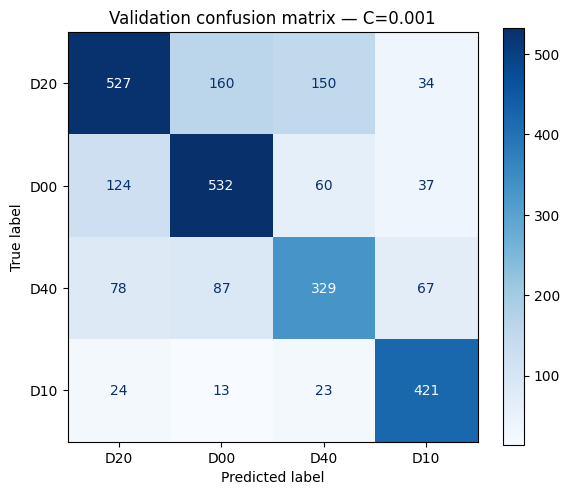


Chosen C: 0.001
Total training and evaluation seconds: 304.0
Test data was not used.


In [ ]:
# Train HOG + SVM candidates and compare training vs validation.
# Test data is not used in this cell.

start = time.perf_counter()

C_VALUES = [0.001, 0.003, 0.01, 0.1, 1.0]
CLASS_IDS = sorted(NAMES)
CLASS_NAMES = [NAMES[cid] for cid in CLASS_IDS]

X_train, y_train = HOG_DATA["train"]
X_val, y_val = HOG_DATA["val"]

hog_trials = []
hog_models = {}

for C in C_VALUES:
    trial_start = time.perf_counter()
    print(f"Training SVM with C={C}...", flush=True)

    pipeline = make_pipeline(
        StandardScaler(),
        LinearSVC(
            C=C,
            class_weight="balanced",
            random_state=SEED,
            max_iter=10000
        )
    )

    # Scaling is fitted on training data only.
    pipeline.fit(X_train, y_train)

    train_pred = pipeline.predict(X_train)
    val_pred = pipeline.predict(X_val)

    train_f1 = f1_score(
        y_train, train_pred,
        labels=CLASS_IDS,
        average="macro",
        zero_division=0
    )

    val_f1 = f1_score(
        y_val, val_pred,
        labels=CLASS_IDS,
        average="macro",
        zero_division=0
    )

    gap = train_f1 - val_f1
    elapsed = time.perf_counter() - trial_start

    hog_trials.append({
        "C": C,
        "train_macro_f1": train_f1,
        "val_macro_f1": val_f1,
        "train_val_gap": gap,
        "seconds": elapsed
    })

    hog_models[C] = pipeline

    print(
        f"Done | Train F1: {train_f1:.3f} | "
        f"Validation F1: {val_f1:.3f} | "
        f"Gap: {gap:.3f} | Time: {elapsed:.1f}s",
        flush=True
    )

hog_trials = pd.DataFrame(hog_trials)

# Select by validation performance only.
# Prefer stronger regularization (smaller C) in an exact tie.
best_row = hog_trials.sort_values(
    ["val_macro_f1", "C"],
    ascending=[False, True]
).iloc[0]

HOG_C = float(best_row["C"])
HOG_MODEL = hog_models[HOG_C]
HOG_TRAIN_SECONDS = time.perf_counter() - start

print("\nTraining and validation comparison:")
display(hog_trials.round(4))

# Plot scores across regularization settings.
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    hog_trials["C"],
    hog_trials["train_macro_f1"],
    marker="o",
    label="Training"
)
ax.plot(
    hog_trials["C"],
    hog_trials["val_macro_f1"],
    marker="o",
    label="Validation"
)

ax.set_xscale("log")
ax.set_xlabel("C — larger values mean weaker regularization")
ax.set_ylabel("Macro-F1")
ax.set_title("HOG + SVM: training vs validation")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(OUT / "hog_train_validation.png")
plt.show()

# Inspect validation performance of the selected model.
best_val_pred = HOG_MODEL.predict(X_val)

report = classification_report(
    y_val,
    best_val_pred,
    labels=CLASS_IDS,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

print("\nSelected model — validation classification report:")
display(pd.DataFrame({k:v for k,v in report.items() if isinstance(v,dict)}).T.round(3))
print('Accuracy:', round(float(report['accuracy']), 3))

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    best_val_pred,
    labels=CLASS_IDS,
    display_labels=CLASS_NAMES,
    cmap="Blues",
    ax=ax
)

ax.set_title(f"Validation confusion matrix — C={HOG_C}")
fig.tight_layout()
fig.savefig(OUT / "hog_validation_confusion.png")
plt.show()

# Save artifacts under the names expected by later cells.
joblib.dump(HOG_MODEL, OUT / "hog_svm.joblib")
hog_trials.to_csv(OUT / "hog_validation.csv", index=False)

(OUT / "hog_validation_report.json").write_text(
    json.dumps(report, indent=2)
)

print(f"\nChosen C: {HOG_C}")
print(f"Total training and evaluation seconds: {HOG_TRAIN_SECONDS:.1f}")
print("Test data was not used.")


## 10 · Detector training protocol and overfitting controls

Both detectors start from pretrained weights and fine-tune general visual features for four damage classes. `yolov5nu.pt` is the Ultralytics YOLOv5u model with an anchor-free head, **not the original anchor-based YOLOv5**. `yolov8n.pt` is the planned main model.

The split, resolution, batch size, epoch budget, seed, AdamW optimizer, and weight decay are shared. Because the prepared dataset already contains offline augmentation, additional trainer geometric and color augmentations are disabled. In particular, 90-degree rotations could change the meaning of longitudinal versus transverse cracks. Standard library preprocessing still occurs. Classification dropout is not presented as a detector regularizer.

`patience=10` stops training when the library's internal validation criterion does not improve. `best.pt` is selected by library fitness, not test performance and not necessarily D40 recall. Learning curves and CSV files support overfitting analysis. Regularization benefit cannot be claimed without a controlled comparison.

The helper reuses completed runs only when their recorded specification matches. Incomplete runs require explicit resumption or a new run name. Weights, timing, and configuration are retained.


In [ ]:
TRAIN_ARGS=dict(data=str(DATA_YAML),epochs=EPOCHS,imgsz=IMGSZ,batch=BATCH,
    patience=PATIENCE,seed=SEED,workers=2,device=DEVICE,optimizer='AdamW',lr0=0.001,
    weight_decay=0.0005,deterministic=True,amp=True,cache=False,save=True,save_period=5,
    project=str(RUNS),plots=True,exist_ok=False,
    mosaic=0.0,mixup=0.0,copy_paste=0.0,degrees=0.0,translate=0.0,scale=0.0,
    shear=0.0,perspective=0.0,fliplr=0.0,flipud=0.0,hsv_h=0.0,hsv_s=0.0,hsv_v=0.0)
EXPERIMENTS={'yolov5u_n':'yolov5nu.pt','yolov8_n':'yolov8n.pt'}
# Existing finished runs are reused only if the full configuration matches.
MODEL_PATHS=globals().get('MODEL_PATHS',{}); TRAIN_TIMES=globals().get('TRAIN_TIMES',{})
EXPERIMENT_SPEC={'train_args':TRAIN_ARGS,'models':EXPERIMENTS,'data_sha256':ARCHIVE_SHA256,
                 'git_commit':REPO_COMMIT,'versions':versions}
(OUT/'experiment_spec.json').write_text(json.dumps(EXPERIMENT_SPEC,indent=2))
def train_detector(name,weights):
    if not RUN_TRAINING:
        print('Training disabled; reuse restored weights:', name)
        return
    if DEVICE=='cpu': raise RuntimeError('Enable a Colab GPU, rerun cell 2, then rerun subsequent cells.')
    run_dir=RUNS/name; stamp=run_dir/'roadguard_complete.json'
    spec={**EXPERIMENT_SPEC,'name':name,'weights':weights}
    if stamp.exists():
        prior=json.loads(stamp.read_text())
        if prior['spec']!=spec: raise RuntimeError('Configuration changed. Choose a new run name.')
        best=run_dir/'weights/best.pt'
        if not best.exists(): raise FileNotFoundError(best)
        MODEL_PATHS[name]=best; TRAIN_TIMES[name]=prior['seconds']; print('Reusing',best); return
    if run_dir.exists():
        raise RuntimeError(f'Incomplete run at {run_dir}; use resume instructions below or choose a new run name.')
    started=time.perf_counter()
    model=YOLO(weights); model.train(**TRAIN_ARGS,name=name)
    elapsed=time.perf_counter()-started
    best=Path(model.trainer.save_dir)/'weights/best.pt'
    if not best.exists(): raise FileNotFoundError(best)
    stamp.write_text(json.dumps({'spec':spec,'seconds':elapsed},indent=2))
    MODEL_PATHS[name]=best; TRAIN_TIMES[name]=elapsed
    del model
    torch.cuda.empty_cache()


### 10a · Restore all four completed experiments

This cell first reuses existing run directories. For a missing run it looks for its named ZIP in the runtime root (normally /content), validates every archive member, and extracts only the expected run. Upload trusted team backups using the Files panel. It registers all four best checkpoints, saves copies with the corrected semantic names, and recovers training durations when recorded. It does not train or overwrite original checkpoints. Missing backups are printed; all four are required for the final export.

**Output provenance:** The saved output below is retained from the original Colab execution. The code in this cell was subsequently edited for the repository and has not been rerun. Default replay guards may now skip work that the historical output records. No numeric result has been recalculated or changed.

In [ ]:
BACKUPS = {
    'yolov5u_n': 'RoadGuard_YOLOv5u_Run01.zip',
    'yolov8_n': 'RoadGuard_YOLOv8_Run01.zip',
    'yolov8_n_lr0003': 'RoadGuard_YOLOv8_LowerLR_Run02.zip',
    'yolov8_n_lr0003_coloraug': 'RoadGuard_YOLOv8_ColorAug_Run03.zip',
}
for name, filename in BACKUPS.items():
    run_dir=RUNS/name
    source=run_dir/'weights/best.pt'
    if not source.is_file():
        archive=ROOT.parent/filename
        if not archive.is_file():
            print('Not restored:',name,'— upload',filename,'to',ROOT.parent)
            continue
        with zipfile.ZipFile(archive) as z:
            expected=f'{name}/weights/best.pt'
            if expected not in z.namelist(): raise ValueError(f'Missing {expected}')
            for item in z.infolist():
                target=(RUNS/item.filename).resolve()
                if not target.is_relative_to(run_dir.resolve()):
                    raise ValueError('Unexpected backup member: '+item.filename)
                if ((item.external_attr >> 16)&0o170000)==0o120000:
                    raise ValueError('Symbolic links are not accepted')
            if run_dir.exists():
                raise RuntimeError(f'Incomplete existing run: {run_dir}; preserve it and inspect before restoring.')
            z.extractall(RUNS)
    corrected=run_dir/'corrected_weights'; corrected.mkdir(exist_ok=True)
    for filename in ['best.pt','last.pt']:
        checkpoint=run_dir/'weights'/filename
        if checkpoint.is_file():
            m=YOLO(str(checkpoint)); m.model.names=NAMES.copy()
            m.save(str(corrected/filename)); del m
    MODEL_PATHS[name]=corrected/'best.pt'
    duration=TRAIN_TIMES.get(name)
    for metadata,key in [('roadguard_complete.json','seconds'),('experiment_note.json','training_seconds')]:
        p=run_dir/metadata
        if duration is None and p.is_file(): duration=json.loads(p.read_text()).get(key)
    TRAIN_TIMES[name]=duration
    print('Registered:',name,MODEL_PATHS[name])
print('Recovery finished. No training was performed.')


Restored: yolov5u_n
Corrected weights: /content/roadguard/runs/yolov5u_n/corrected_weights/best.pt
Restored: yolov8_n
Corrected weights: /content/roadguard/runs/yolov8_n/corrected_weights/best.pt

Restoration completed. No training was performed.


### 10b · Historical lower-learning-rate experiment — disabled by default

This records the completed comparison that changed lr0 from 0.001 to 0.0003 while starting from pretrained YOLOv8n weights. RUN_TRAINING=False skips the whole cell. Leave it disabled and restore the saved run. Enabling it would create a new training run and is not needed to finish this project phase.

**Output provenance:** The saved output below is retained from the original Colab execution. The code in this cell was subsequently edited for the repository and has not been rerun. Default replay guards may now skip work that the historical output records. No numeric result has been recalculated or changed.

In [ ]:
if RUN_TRAINING:
    # Experiment 2: YOLOv8 with a lower initial learning rate.
    # Start from the original pretrained weights, not the previous run.
    # Keep all other training settings unchanged.

    from pathlib import Path
    import time
    import json
    import shutil
    from ultralytics import YOLO
    from google.colab import files

    # Verify that the corrected class mapping is active.
    expected_names = {
        0: "D20",
        1: "D00",
        2: "D40",
        3: "D10"
    }

    if NAMES != expected_names or POTHOLE_ID != 2:
        raise RuntimeError(
            "Run the class-mapping correction cell before this experiment."
        )

    yaml_config = yaml.safe_load(DATA_YAML.read_text())
    yaml_names = yaml_config["names"]

    if isinstance(yaml_names, list):
        yaml_names = dict(enumerate(yaml_names))
    else:
        yaml_names = {int(k): v for k, v in yaml_names.items()}

    if yaml_names != expected_names:
        raise RuntimeError(
            "The runtime YAML still contains the old class names."
        )

    if not torch.cuda.is_available():
        raise RuntimeError("A GPU is required for this training run.")

    # Use a new directory so previous experiments remain intact.
    NEW_NAME = "yolov8_n_lr0003"
    new_run_dir = RUNS / NEW_NAME

    if new_run_dir.exists():
        raise RuntimeError(
            f"This experiment directory already exists: {new_run_dir}. "
            "Do not overwrite it."
        )

    # Copy the original settings without changing TRAIN_ARGS.
    new_args = TRAIN_ARGS.copy()
    new_args["data"] = str(DATA_YAML)
    new_args["lr0"] = 0.0003
    new_args["name"] = NEW_NAME

    print("Starting experiment:", NEW_NAME)
    print("Initial learning rate:", new_args["lr0"])
    print("Maximum epochs:", new_args["epochs"])
    print("Early-stopping patience:", new_args["patience"])

    started = time.perf_counter()

    new_model = YOLO("yolov8n.pt")
    new_model.train(**new_args)

    elapsed = time.perf_counter() - started

    # Register the completed experiment for later comparisons.
    actual_run_dir = Path(new_model.trainer.save_dir)
    best_path = actual_run_dir / "weights" / "best.pt"

    if not best_path.is_file():
        raise FileNotFoundError(best_path)

    MODEL_PATHS[NEW_NAME] = best_path
    TRAIN_TIMES[NEW_NAME] = elapsed

    # Record the experiment change.
    experiment_note = {
        "name": NEW_NAME,
        "starting_weights": "yolov8n.pt",
        "changed_parameter": "lr0",
        "previous_value": 0.001,
        "new_value": 0.0003,
        "class_mapping": NAMES,
        "training_seconds": elapsed
    }

    (actual_run_dir / "experiment_note.json").write_text(
        json.dumps(experiment_note, indent=2)
    )

    print("\nTraining finished.")
    print("Best weights:", best_path)

    # Back up the new run and download it.
    zip_path = shutil.make_archive(
        base_name=str(ROOT / "RoadGuard_YOLOv8_LowerLR_Run02"),
        format="zip",
        root_dir=actual_run_dir.parent,
        base_dir=actual_run_dir.name
    )

    print("Backup ready:", zip_path)
    files.download(zip_path)
else:
    print('Historical experiment: training skipped. Use the recovery cell to register its saved weights.')


Starting experiment: yolov8_n_lr0003
Initial learning rate: 0.0003
Maximum epochs: 30
Early-stopping patience: 10
New https://pypi.org/project/ultralytics/8.4.185 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/roadguard/data_runtime.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, kobj

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 10c · Historical mild-color-augmentation experiment — disabled by default

This records the completed comparison that kept lr0=0.0003 and enabled HSV changes (0.01, 0.20, 0.20). It starts from pretrained weights and preserves prior run directories. RUN_TRAINING=False skips training and its intermediate download; use the recovery cell to load the existing result.

**Output provenance:** The saved output below is retained from the original Colab execution. The code in this cell was subsequently edited for the repository and has not been rerun. Default replay guards may now skip work that the historical output records. No numeric result has been recalculated or changed.

In [ ]:
if RUN_TRAINING:
    # Experiment 3: YOLOv8 with mild color augmentation.
    # Compare against Experiment 2: same settings, plus HSV augmentation.
    # Start from the original pretrained weights.

    from pathlib import Path
    import json
    import time
    import shutil
    import yaml
    import torch
    from ultralytics import YOLO
    from google.colab import files

    NEW_NAME = "yolov8_n_lr0003_coloraug"
    run_dir = RUNS / NEW_NAME

    expected_names = {
        0: "D20",
        1: "D00",
        2: "D40",
        3: "D10"
    }

    if NAMES != expected_names or POTHOLE_ID != 2:
        raise RuntimeError("The corrected class mapping is not active.")

    config = yaml.safe_load(DATA_YAML.read_text())
    raw_names = config["names"]
    yaml_names = (
        dict(enumerate(raw_names))
        if isinstance(raw_names, list)
        else {int(k): v for k, v in raw_names.items()}
    )

    if yaml_names != expected_names:
        raise RuntimeError("The dataset YAML has an incorrect class mapping.")

    if not torch.cuda.is_available():
        raise RuntimeError("Connect to a GPU before training.")

    if run_dir.exists():
        raise RuntimeError(
            f"Experiment directory already exists: {run_dir}. "
            "Previous files were not overwritten."
        )

    # Preserve the original settings and experiment registry.
    args = TRAIN_ARGS.copy()
    args.update({
        "data": str(DATA_YAML),
        "name": NEW_NAME,
        "lr0": 0.0003,
        "hsv_h": 0.01,
        "hsv_s": 0.20,
        "hsv_v": 0.20
    })

    print("Experiment:", NEW_NAME)
    print("Learning rate:", args["lr0"])
    print("Color augmentation:",
          {key: args[key] for key in ["hsv_h", "hsv_s", "hsv_v"]})

    started = time.perf_counter()

    model = YOLO("yolov8n.pt")
    model.train(**args)

    elapsed = time.perf_counter() - started
    actual_dir = Path(model.trainer.save_dir)
    best_path = actual_dir / "weights" / "best.pt"

    if not best_path.is_file():
        raise FileNotFoundError(best_path)

    MODEL_PATHS[NEW_NAME] = best_path
    TRAIN_TIMES[NEW_NAME] = elapsed

    note = {
        "name": NEW_NAME,
        "starting_weights": "yolov8n.pt",
        "comparison_run": "yolov8_n_lr0003",
        "changed_parameters": {
            "hsv_h": {"before": 0.0, "after": 0.01},
            "hsv_s": {"before": 0.0, "after": 0.20},
            "hsv_v": {"before": 0.0, "after": 0.20}
        },
        "class_mapping": NAMES,
        "training_seconds": elapsed,
        "training_arguments": args
    }

    (actual_dir / "experiment_note.json").write_text(
        json.dumps(note, indent=2, default=str)
    )

    zip_path = shutil.make_archive(
        base_name=str(ROOT / "RoadGuard_YOLOv8_ColorAug_Run03"),
        format="zip",
        root_dir=actual_dir.parent,
        base_dir=actual_dir.name
    )

    print("\nTraining finished.")
    print("Best weights:", best_path)
    print("Backup ready:", zip_path)

    files.download(zip_path)
else:
    print('Historical experiment: training skipped. Use the recovery cell to register its saved weights.')


Experiment: yolov8_n_lr0003_coloraug
Learning rate: 0.0003
Color augmentation: {'hsv_h': 0.01, 'hsv_s': 0.2, 'hsv_v': 0.2}
New https://pypi.org/project/ultralytics/8.4.185 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/roadguard/data_runtime.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.2, hsv_v=0.2, imgsz=640, iou

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11 · Train YOLOv5u as a detector comparison

This cell trains the small YOLOv5u detector using the shared helper. It provides an additional detection baseline beyond the traditional classifier required by the charter. Each epoch reports training losses and validation metrics. Runtime depends on hardware and dataset size.

`last.pt` supports continuation, while `best.pt` is used for evaluation. Do not assume the last checkpoint is best. If interrupted in the same environment, training can be resumed with `YOLO(str(RUNS/'yolov5u_n/weights/last.pt')).train(resume=True)`. After a completed manual resume, register its checkpoint in MODEL_PATHS and accumulated timing in TRAIN_TIMES, or start a new experiment under a new name. Do not change experiment settings during resumption.


**Output provenance:** The saved output below is retained from the original Colab execution. The code in this cell was subsequently edited for the repository and has not been rerun. Default replay guards may now skip work that the historical output records. No numeric result has been recalculated or changed.

In [ ]:
train_detector('yolov5u_n',EXPERIMENTS['yolov5u_n'])
print('Registered best weights:',MODEL_PATHS.get('yolov5u_n','not restored'))


Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/roadguard/data_runtime.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov5nu.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=yolov5u_n, nbs=64, nms=None, opset=None, optimize=Fal

### 11a · Optional intermediate backup

This historical backup cell archives the original YOLOv5u run and downloads it only when training mode is enabled. In the completion workflow it skips. Section 23 produces the combined handoff ZIP.

**Output provenance:** The saved output below is retained from the original Colab execution. The code in this cell was subsequently edited for the repository and has not been rerun. Default replay guards may now skip work that the historical output records. No numeric result has been recalculated or changed.

In [ ]:
if RUN_TRAINING:
    from pathlib import Path
    import shutil
    from google.colab import files

    # Locate the completed experiment.
    run_dir = Path("/content/roadguard/runs/yolov5u_n")

    if not (run_dir / "weights/best.pt").is_file():
        raise FileNotFoundError(
            f"Best model weights were not found in: {run_dir}"
        )

    # Archive the entire run, including weights, settings and metrics.
    zip_path = shutil.make_archive(
        base_name="/content/RoadGuard_YOLOv5u_Run01",
        format="zip",
        root_dir=run_dir.parent,
        base_dir=run_dir.name
    )

    print(f"Saved archive: {zip_path}")
    files.download(zip_path)
else:
    print('Intermediate backup skipped. Section 23 exports all restored models together.')


Saved archive: /content/RoadGuard_YOLOv5u_Run01.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12 · Train YOLOv8n, the planned main model

This cell applies the same training process to YOLOv8n. Preserving the split and training budget makes the detector comparison more interpretable. The pretrained weights and architectures differ, so this is a comparison of systems under a common budget rather than a study isolating every architectural difference.

No test evaluation occurs here. If YOLOv8 does not outperform the comparison detector, report that result honestly: calling it the planned main model does not establish superior performance.


**Output provenance:** The saved output below is retained from the original Colab execution. The code in this cell was subsequently edited for the repository and has not been rerun. Default replay guards may now skip work that the historical output records. No numeric result has been recalculated or changed.

In [ ]:
train_detector('yolov8_n',EXPERIMENTS['yolov8_n'])
print('Registered best weights:',MODEL_PATHS.get('yolov8_n','not restored'))


Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/roadguard/data_runtime.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=yolov8_n, nbs=64, nms=None, opset=None, optimize=False

### 12a · Optional intermediate backup

This historical backup cell archives the original YOLOv8 run and downloads it only when training mode is enabled. Leave training disabled for the completion workflow. Section 23 backs up the registered models and all reports together.

**Output provenance:** The saved output below is retained from the original Colab execution. The code in this cell was subsequently edited for the repository and has not been rerun. Default replay guards may now skip work that the historical output records. No numeric result has been recalculated or changed.

In [ ]:
if RUN_TRAINING:
    from pathlib import Path
    import shutil
    from google.colab import files

    # Locate the completed YOLOv8 run.
    run_dir = Path("/content/roadguard/runs/yolov8_n")

    if not (run_dir / "weights/best.pt").is_file():
        raise FileNotFoundError(
            f"Best model weights were not found in: {run_dir}"
        )

    # Back up the entire run: weights, settings, metrics and plots.
    zip_path = shutil.make_archive(
        base_name="/content/RoadGuard_YOLOv8_Run01",
        format="zip",
        root_dir=run_dir.parent,
        base_dir=run_dir.name
    )

    print(f"Backup ready: {zip_path}")
    files.download(zip_path)
else:
    print('Intermediate backup skipped. Section 23 exports all restored models together.')


Backup ready: /content/RoadGuard_YOLOv8_Run01.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13 · Learning curves and overfitting diagnosis

This cell reads each run's results.csv and plots training/validation box loss and validation mAP over epochs. Look for sustained improvement in training loss while validation loss rises or validation metrics decline. The gap alone does not prove overfitting, because training and validation losses are measured under different conditions.

Architecture comparisons do not isolate augmentation effects. If learning rate, weight decay, freezing, or augmentation needs adjustment, create a new experiment and select it using validation **before** final test evaluation. Improving the model in response to test results makes that test set part of development and requires a fresh independent test for a final unbiased estimate. Curves and training durations are saved or displayed.


**Output provenance:** The saved output below is retained from the original Colab execution. The code in this cell was subsequently edited for the repository and has not been rerun. Default replay guards may now skip work that the historical output records. No numeric result has been recalculated or changed.

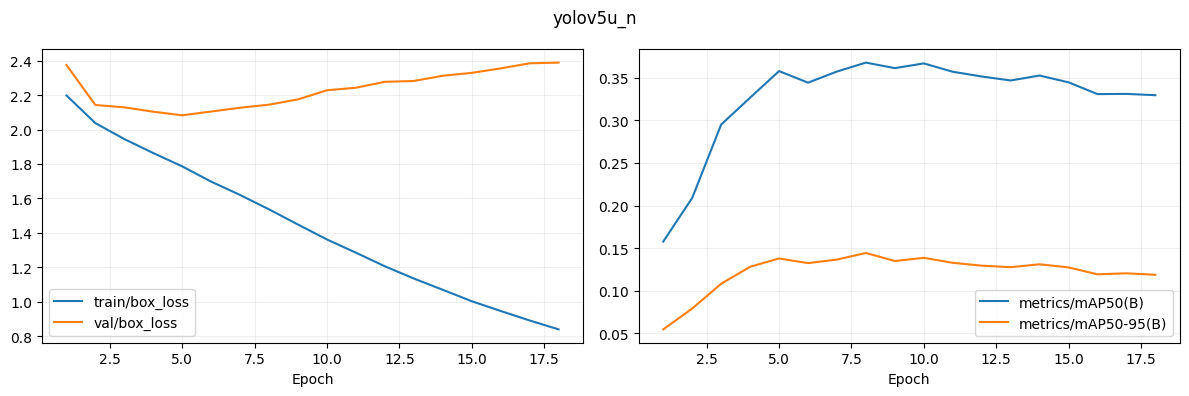

yolov5u_n Completed epochs: 18 Training seconds: 3248.1


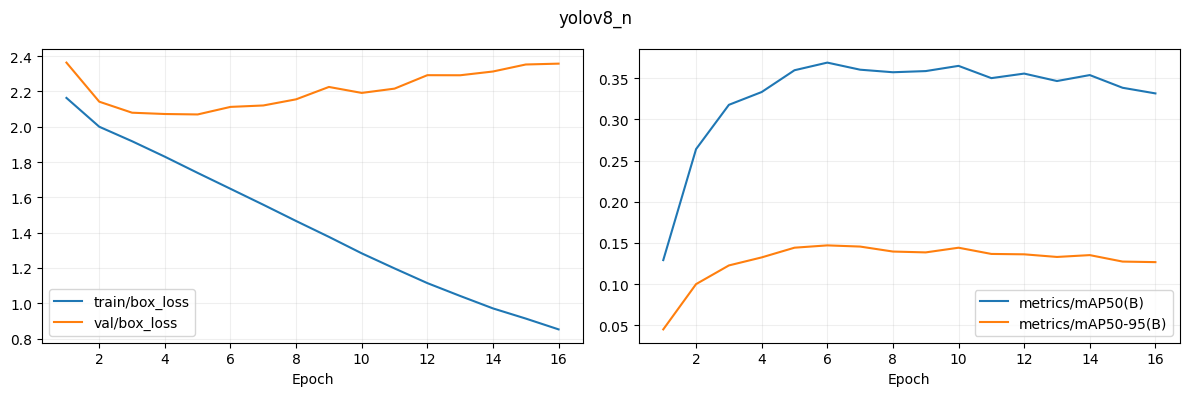

yolov8_n Completed epochs: 16 Training seconds: 2740.8


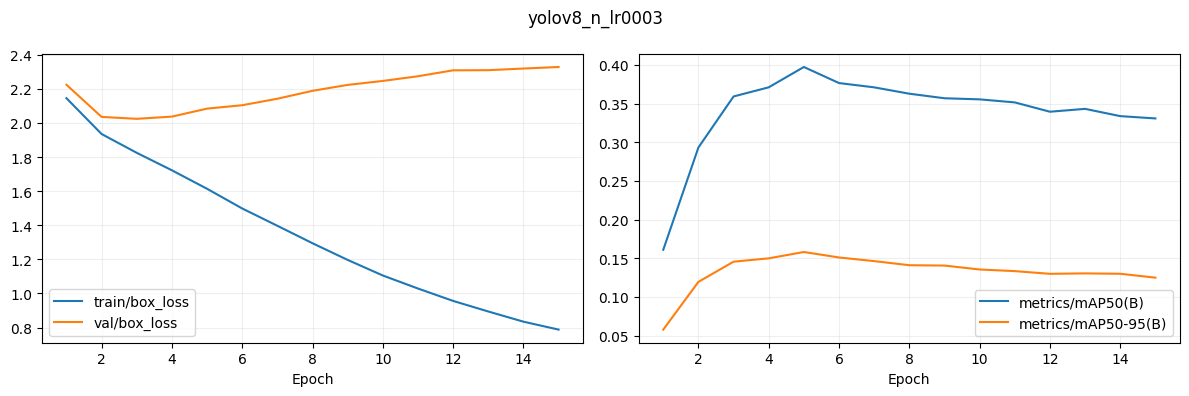

yolov8_n_lr0003 Completed epochs: 15 Training seconds: 2767.8


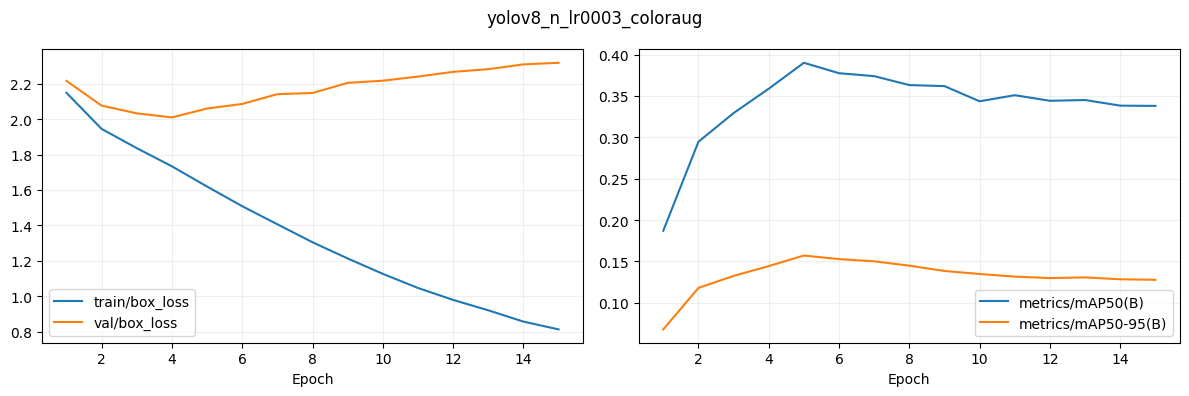

yolov8_n_lr0003_coloraug Completed epochs: 15 Training seconds: 3208.6


In [ ]:
for name in MODEL_PATHS:
    frame=pd.read_csv(RUNS/name/'results.csv'); frame.columns=frame.columns.str.strip()
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for col in ['train/box_loss','val/box_loss']:
        if col in frame: axes[0].plot(frame['epoch'],frame[col],label=col)
    for col in ['metrics/mAP50(B)','metrics/mAP50-95(B)']:
        if col in frame: axes[1].plot(frame['epoch'],frame[col],label=col)
    for ax in axes: ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=.2)
    fig.suptitle(name); plt.tight_layout(); plt.savefig(OUT/f'{name}_learning_curves.png'); plt.show()
    print(name,'Completed epochs:',len(frame),'Training seconds:',round(TRAIN_TIMES[name],1) if TRAIN_TIMES.get(name) is not None else 'not recorded')


### 13a · Validation image comparison

This samples at most six validation images with ground-truth potholes, using seed 42. It displays annotations beside predictions from the original two detectors at confidence 0.25. This is an illustrative diagnostic, not the final operating threshold or a model-selection rule. It saves the figure without training.

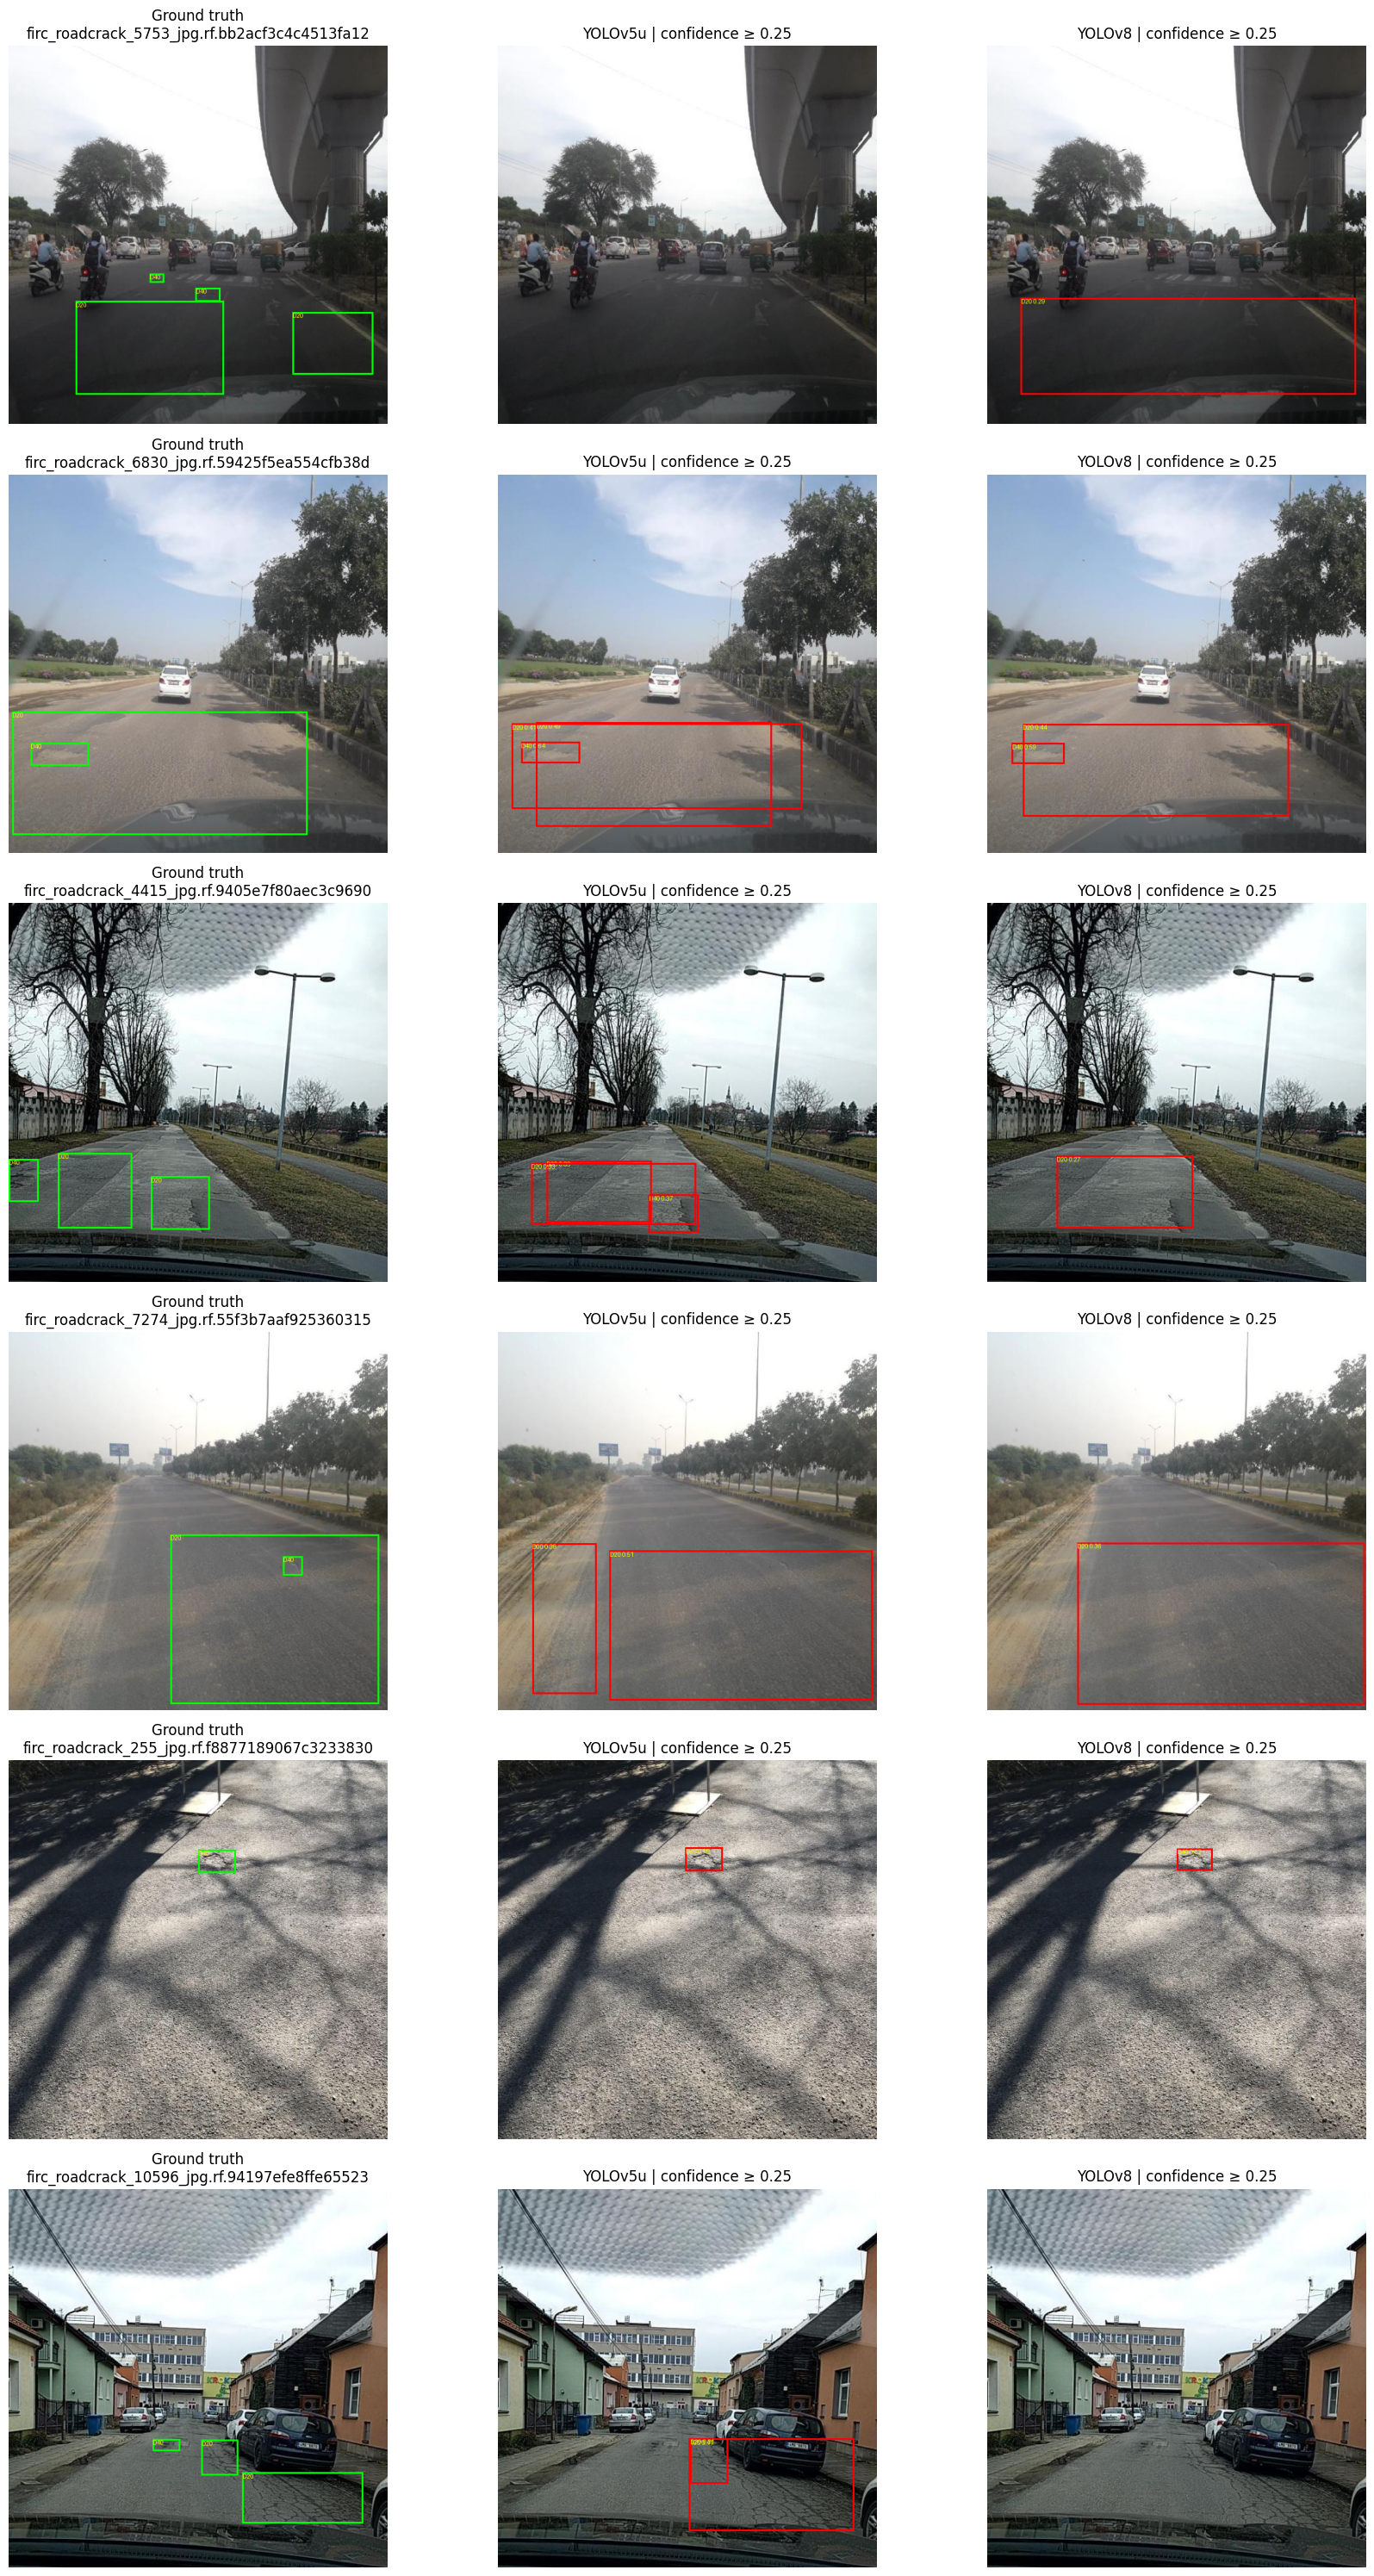

In [ ]:
# Compare ground truth and both detectors on validation images only.

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Select a reproducible sample containing pothole annotations.
val_rows = manifest.loc[manifest["split"] == "val"].copy()

pothole_mask = val_rows["path"].apply(
    lambda path: any(
        int(box[0]) == POTHOLE_ID
        for box in labels_by_path[str(path)]
    )
)

pool = val_rows.loc[pothole_mask]

if pool.empty:
    raise ValueError(
        "No validation images contain the declared pothole class."
    )

sample = pool.sample(
    n=min(6, len(pool)),
    random_state=SEED
)

# This threshold is for visual inspection only.
# It is not the final operating threshold.
VISUAL_CONF = 0.25

models = {
    "YOLOv5u": YOLO(str(MODEL_PATHS["yolov5u_n"])),
    "YOLOv8": YOLO(str(MODEL_PATHS["yolov8_n"]))
}

fig, axes = plt.subplots(
    len(sample), 3,
    figsize=(18, 5 * len(sample)),
    squeeze=False
)

for row_index, (_, row) in enumerate(sample.iterrows()):
    path = str(row["path"])

    # Ground-truth annotations.
    axes[row_index, 0].imshow(
        draw_boxes(path, gt_xyxy(path))
    )
    axes[row_index, 0].set_title(
        f"Ground truth\n{Path(path).name[:45]}"
    )

    # Predictions from each trained detector.
    for column, (name, model) in enumerate(
        models.items(), start=1
    ):
        result = model.predict(
            source=path,
            imgsz=IMGSZ,
            conf=VISUAL_CONF,
            iou=NMS_IOU,
            device=DEVICE,
            verbose=False
        )[0]

        boxes = result.boxes

        predictions = np.column_stack([
            boxes.cls.cpu().numpy(),
            boxes.xyxy.cpu().numpy(),
            boxes.conf.cpu().numpy()
        ])

        axes[row_index, column].imshow(
            draw_boxes(path, predictions, pred=True)
        )
        axes[row_index, column].set_title(
            f"{name} | confidence ≥ {VISUAL_CONF}"
        )

    for ax in axes[row_index]:
        ax.axis("off")

plt.tight_layout()
plt.savefig(
    OUT / "validation_visual_comparison.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

### 13b · Display the verified class order

This reapplies the known numeric-to-semantic mapping and prints pothole ID 2. It changes names in memory only; the next cell records the mapping in runtime YAML and provenance files. It does not relabel annotation IDs or change learned parameters.

In [ ]:
NAMES = {
    0: "D20",
    1: "D00",
    2: "D40",
    3: "D10"
}

POTHOLE_ID = 2
print("Current class mapping:", NAMES)
print("Pothole class ID:", POTHOLE_ID)

Current class mapping: {0: 'D20', 1: 'D00', 2: 'D40', 3: 'D10'}
Pothole class ID: 2


### 13c · Record the mapping correction

This records the mapping established by the user-supplied original Roboflow YAML and the repository preprocessing that retains numeric IDs. It updates runtime YAML and class_mapping.json. The generic processed names do not establish semantic order by themselves. Old training plots may retain old names; use numeric IDs and corrected reports.

In [ ]:
# Correct class names without changing labels or retraining models.
import json
import yaml

NAMES = {
    0: "D20",  # Alligator cracks
    1: "D00",  # Longitudinal cracks
    2: "D40",  # Potholes
    3: "D10"   # Transverse cracks
}

DECLARED_MAPPING = NAMES.copy()
POTHOLE_ID = 2

MAPPING_VERIFIED = True
MAPPING_STATUS = (
    "Source Roboflow YAML supplied by user; "
    "repository preprocessing preserves class IDs."
)

# Update the runtime YAML used by subsequent evaluations.
runtime_config = yaml.safe_load(DATA_YAML.read_text())
runtime_config["names"] = NAMES.copy()

DATA_YAML.write_text(
    yaml.safe_dump(runtime_config, sort_keys=False)
)

(OUT / "data_runtime.yaml").write_text(DATA_YAML.read_text())

# Record the correction alongside the original run artifacts.
(OUT / "class_mapping.json").write_text(
    json.dumps({
        "original": ORIGINAL_NAMES,
        "used": NAMES,
        "status": MAPPING_STATUS,
        "verified": MAPPING_VERIFIED,
        "source_names": [
            "AlligatorCrack",
            "LongitudinalCracks",
            "Potholes",
            "TransverseCrack"
        ]
    }, indent=2)
)

print("Class mapping corrected:")
for class_id, name in NAMES.items():
    print(f"Class {class_id} -> {name}")

print(f"\nPothole class ID: {POTHOLE_ID}")
print("Runtime YAML updated.")
print("Training weights and numeric labels were not changed.")

Class mapping corrected:
Class 0 -> D20
Class 1 -> D00
Class 2 -> D40
Class 3 -> D10

Pothole class ID: 2
Runtime YAML updated.
Training weights and numeric labels were not changed.


## 14 · Prediction and ground-truth matching functions

Operating-point recall requires explicit matching rules. Predictions are generated with a low confidence floor of 0.001, then filtered at candidate operating thresholds without retraining. NMS uses IoU=0.70 to suppress duplicate detections; this is distinct from the ground-truth matching criterion.

A prediction is a true positive only when its class is correct and its IoU with an unmatched ground-truth box is at least 0.50. Predictions are processed from highest confidence downward, and each ground-truth box can match once. A wrong class creates a false positive for the predicted class and a false negative for the true class. Classes without ground-truth support have undefined recall.

Official Ultralytics evaluation calculates mAP separately. These helpers calculate operating-point metrics, image-level errors, and country summaries. YOLO confidence scores are not calibrated probabilities.


In [12]:
def predict_paths(model,paths):
    predictions={}
    for start in tqdm(range(0,len(paths),32),desc='Predict batches'):
        batch_paths=paths[start:start+32]
        results=model.predict(source=batch_paths,imgsz=IMGSZ,conf=PRED_FLOOR,iou=NMS_IOU,
                              max_det=300,device=DEVICE,verbose=False,stream=False)
        for path,result in zip(batch_paths,results):
            b=result.boxes
            predictions[str(path)]=np.column_stack([b.cls.cpu().numpy(),b.xyxy.cpu().numpy(),b.conf.cpu().numpy()])
    return predictions

def iou_one(box,boxes):
    if not len(boxes): return np.zeros(0)
    lo=np.maximum(box[:2],boxes[:,:2]); hi=np.minimum(box[2:],boxes[:,2:])
    inter=np.maximum(hi-lo,0).prod(axis=1)
    area=max(0,box[2]-box[0])*max(0,box[3]-box[1])
    other=np.maximum(boxes[:,2:]-boxes[:,:2],0).prod(axis=1)
    return inter/np.maximum(area+other-inter,1e-12)

def match_image(gt,pred,threshold):
    pred=pred[pred[:,5]>=threshold] if len(pred) else np.empty((0,6))
    pred=pred[np.argsort(-pred[:,5],kind='stable')]
    used=set(); tp=Counter(); fp=Counter()
    for p in pred:
        cid=int(p[0]); ids=[i for i,g in enumerate(gt) if int(g[0])==cid and i not in used]
        scores=iou_one(p[1:5],gt[ids,1:5])
        if len(scores) and scores.max()>=MATCH_IOU:
            used.add(ids[int(scores.argmax())]); tp[cid]+=1
        else: fp[cid]+=1
    fn=Counter(int(g[0]) for i,g in enumerate(gt) if i not in used)
    return tp,fp,fn

def score_predictions(predictions,paths,threshold):
    totals={k:Counter() for k in ['tp','fp','fn']}; image_rows=[]
    for p in paths:
        counts=match_image(gt_xyxy(p),predictions[str(p)],threshold)
        row={'path':str(p),'country':country_from_name(Path(p).name)}
        for key,values in zip(totals,counts):
            totals[key].update(values); row[key]=sum(values.values())
        row['d40_fn']=counts[2][POTHOLE_ID]; image_rows.append(row)
    rows=[]
    for cid in NAMES:
        tp,fp,fn=[totals[k][cid] for k in ['tp','fp','fn']]
        precision=tp/(tp+fp) if tp+fp else 0.0
        recall=tp/(tp+fn) if tp+fn else np.nan
        f1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else np.nan
        rows.append({'class_id':cid,'class':NAMES[cid],'tp':tp,'fp':fp,'fn':fn,
                     'support':tp+fn,'precision':precision,'recall':recall,'f1':f1})
    return pd.DataFrame(rows),pd.DataFrame(image_rows)


## 15 · Validation: choose thresholds and freeze the detector

For each detector, this cell evaluates the predefined confidence-threshold grid on validation only. Among thresholds achieving D40 recall ≥0.80, it selects the one with highest D40 precision, preferring a higher threshold in a tie. If none reaches the recall target, it selects maximum F1 and records that the target was missed. One threshold applies to all classes.

Official validation mAP50 and mAP50–95 are also collected. The deployment candidate is ranked by meeting both validation targets, then D40 recall, then mAP50, with YOLOv8 preferred in a complete tie. The model and thresholds are saved **before test evaluation**. Metrics calculated under a provisional mapping do not verify the semantic D40 target. No threshold is selected from test outcomes.

If frozen results already exist in this runtime, this cell displays and reuses them. Otherwise it requires ALLOW_VALIDATION_EVALUATION=True before reproducing the existing protocol. No new hyperparameter trial is introduced.


**Output provenance:** The saved output below is retained from the original Colab execution. The code in this cell was subsequently edited for the repository and has not been rerun. Default replay guards may now skip work that the historical output records. No numeric result has been recalculated or changed.

In [ ]:
if all(k in globals() for k in ['VAL_PREDS','SELECTED_THRESHOLDS','CHOSEN_MODEL','LOCK','val_summary']):
    print('Reusing existing frozen validation results.'); display(val_summary)
elif ALLOW_VALIDATION_EVALUATION:
    VAL_PATHS=manifest.loc[manifest.split=='val','path'].tolist()
    VAL_PREDS={}; VAL_SUMMARY=[]; SELECTED_THRESHOLDS={}; VAL_METRICS={}
    for name,path in MODEL_PATHS.items():
        model=YOLO(str(path))
        metrics=model.val(data=str(DATA_YAML),split='val',imgsz=IMGSZ,batch=BATCH,device=DEVICE,
                          conf=PRED_FLOOR,iou=NMS_IOU,plots=True,project=str(RUNS),name=f'{name}_val',exist_ok=True)
        VAL_METRICS[name]={'map50':float(metrics.box.map50),'map50_95':float(metrics.box.map)}
        predictions=predict_paths(model,VAL_PATHS); VAL_PREDS[name]=predictions
        rows=[]
        for threshold in THRESHOLDS:
            table,_=score_predictions(predictions,VAL_PATHS,threshold)
            r=table.loc[table.class_id==POTHOLE_ID].iloc[0]
            rows.append({'threshold':threshold,'precision':r.precision,'recall':r.recall,'f1':r.f1})
        sweep=pd.DataFrame(rows); eligible=sweep.loc[sweep.recall>=RECALL_TARGET]
        if len(eligible): chosen=eligible.sort_values(['precision','threshold'],ascending=False).iloc[0]
        else: chosen=sweep.sort_values(['f1','recall','threshold'],ascending=False).iloc[0]
        SELECTED_THRESHOLDS[name]=float(chosen.threshold)
        sweep.to_csv(OUT/f'{name}_val_thresholds.csv',index=False)
        row={'model':name,**VAL_METRICS[name],'threshold':float(chosen.threshold),
             'd40_precision':float(chosen.precision),'d40_recall':float(chosen.recall),
             'val_targets_met':bool(chosen.recall>=RECALL_TARGET and metrics.box.map50>=MAP50_TARGET)}
        VAL_SUMMARY.append(row)
        display(sweep); del model
    val_summary=pd.DataFrame(VAL_SUMMARY)
    val_summary['prefer_v8']=val_summary.model.eq('yolov8_n').astype(int)
    ranked=val_summary.sort_values(['val_targets_met','d40_recall','map50','prefer_v8'],ascending=False)
    CHOSEN_MODEL=ranked.iloc[0].model
    LOCK={'chosen_model':CHOSEN_MODEL,'thresholds':SELECTED_THRESHOLDS,
          'matching_iou':MATCH_IOU,'nms_iou':NMS_IOU,'mapping_verified':MAPPING_VERIFIED,
          'selection':'validation only; targets met, then D40 recall, then mAP50, then YOLOv8 tie-break'}
    (OUT/'validation_lock.json').write_text(json.dumps(LOCK,indent=2))
    val_summary.to_csv(OUT/'validation_models.csv',index=False)
    display(val_summary); print('Frozen selected detector:',CHOSEN_MODEL)

else:
    raise RuntimeError('Validation results missing. After recovery, enable ALLOW_VALIDATION_EVALUATION in section 2 to reproduce them; keep the four experiments unchanged.')


Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv5n summary (fused): 85 layers, 2,630,732 parameters, 0 gradients, 7.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2125.5±751.3 MB/s, size: 58.1 KB)
val: Scanning /content/roadguard/dataset_extracted/road_damage_detect/val/labels.cache... 1265 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1265/1265 442.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 159/159 10.9it/s 14.6s
                   all       1265       2666      0.441      0.402      0.369      0.144
                   D20        675        871      0.513      0.564      0.537      0.233
                   D00        520        753      0.397      0.382      0.319       0.12
                   D40        302        561      0.432      0.309      0.298      0.111
                   D10        280        481      0.424      0.351       0.32      0.114
S

Predict batches:   0%|          | 0/40 [00:00<?, ?it/s]

,threshold,precision,recall,f1
0,0.010,0.067843,0.713012,0.123897
1,0.025,0.115981,0.613191,0.195067
2,0.050,0.173862,0.524064,0.261101
3,0.100,0.274531,0.443850,0.339237
4,0.150,0.354785,0.383244,0.368466
5,0.200,0.407745,0.319073,0.358000
6,0.250,0.462428,0.285205,0.352811
7,0.350,0.547511,0.215686,0.309463
8,0.500,0.678899,0.131907,0.220896
9,0.650,0.860465,0.065954,0.122517


Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2444.2±570.2 MB/s, size: 82.0 KB)
val: Scanning /content/roadguard/dataset_extracted/road_damage_detect/val/labels.cache... 1265 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1265/1265 353.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 159/159 10.7it/s 14.8s
                   all       1265       2666      0.454      0.384      0.369      0.147
                   D20        675        871      0.505      0.569      0.524      0.224
                   D00        520        753      0.471      0.353      0.359      0.145
                   D40        302        561      0.445      0.339       0.33      0.124
                   D10        280        481      0.396      0.273      0.263     0.0963
Spe

Predict batches:   0%|          | 0/40 [00:00<?, ?it/s]

...

Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1701.5±375.3 MB/s, size: 68.2 KB)
val: Scanning /content/roadguard/dataset_extracted/road_damage_detect/val/labels.cache... 1265 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1265/1265 379.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 159/159 10.9it/s 14.6s
                   all       1265       2666      0.465       0.41       0.39      0.157
                   D20        675        871      0.532      0.566       0.55       0.24
                   D00        520        753      0.479      0.335      0.338      0.135
                   D40        302        561      0.377      0.401      0.331      0.131
                   D10        280        481       0.47      0.339       0.34      0.123
Spe

Predict batches:   0%|          | 0/40 [00:00<?, ?it/s]

,threshold,precision,recall,f1
0,0.010,0.043048,0.805704,0.081729
1,0.025,0.079064,0.729055,0.142658
2,0.050,0.127846,0.650624,0.213700
3,0.100,0.203516,0.536542,0.295098
4,0.150,0.276749,0.479501,0.350946
5,0.200,0.335684,0.424242,0.374803
6,0.250,0.413592,0.379679,0.395911
7,0.350,0.532110,0.310160,0.391892
8,0.500,0.676471,0.204991,0.314637
9,0.650,0.773333,0.103387,0.182390


,model,map50,map50_95,threshold,d40_precision,d40_recall,val_targets_met,prefer_v8
0,yolov5u_n,0.368582,0.144464,0.15,0.354785,0.383244,False,0
1,yolov8_n,0.369070,0.147288,0.15,0.372650,0.388592,False,1
2,yolov8_n_lr0003,0.395024,0.158059,0.25,0.410609,0.372549,False,0
3,yolov8_n_lr0003_coloraug,0.390000,0.157283,0.01,0.043048,0.805704,False,0


Frozen selected detector: yolov8_n_lr0003_coloraug


### 15a · Historical low-threshold sensitivity diagnostic

This inspects additional validation confidence thresholds and reports D40 precision, recall and false positives. It does not replace SELECTED_THRESHOLDS or the frozen model choice. Very low thresholds can recover more potholes while creating many false alarms. It is not a reason to reopen model tuning after inspecting test data.

In [14]:
# Check additional low thresholds using cached validation predictions.
# No training, new inference, or test evaluation is performed.

rows = []

for name, predictions in VAL_PREDS.items():
    for threshold in [0.001, 0.003, 0.005, 0.01]:
        table, _ = score_predictions(
            predictions, VAL_PATHS, threshold
        )

        pothole = table.loc[
            table["class_id"] == POTHOLE_ID
        ].iloc[0]

        rows.append({
            "model": name,
            "threshold": threshold,
            "precision": pothole["precision"],
            "recall": pothole["recall"],
            "false_positives": int(pothole["fp"]),
            "recall_target_met": bool(
                pothole["recall"] >= RECALL_TARGET
            )
        })

low_threshold_check = pd.DataFrame(rows)
display(low_threshold_check.round(4))

low_threshold_check.to_csv(
    OUT / "validation_low_threshold_check.csv",
    index=False
)

,model,threshold,precision,recall,false_positives,recall_target_met
0,yolov5u_n,0.001,0.0187,0.8645,25515,True
1,yolov5u_n,0.003,0.0333,0.8075,13159,True
2,yolov5u_n,0.005,0.0443,0.7683,9300,False
3,yolov5u_n,0.010,0.0678,0.7130,5496,False
4,yolov8_n,0.001,0.0177,0.8396,26126,True
5,yolov8_n,0.003,0.0332,0.7843,12804,False
6,yolov8_n,0.005,0.0446,0.7504,9016,False
7,yolov8_n,0.010,0.0651,0.6738,5429,False
8,yolov8_n_lr0003,0.001,0.0132,0.8824,36912,True
9,yolov8_n_lr0003,0.003,0.0245,0.8360,18641,True


## 16 · Final test evaluation: detection and charter metrics

Both detectors are now evaluated on test using their frozen validation thresholds. Do not search for a better threshold here. mAP is computed across confidence levels using the low prediction floor, separately from precision and recall at the selected operating point.

For every class, the report saves mAP50, mAP50–95, TP, FP, FN, support, precision, and recall. The code does not use `metrics.box.r` as recall at our selected threshold, because the library summary may refer to a different F1 operating point. Charter-target status is accepted only when the semantic mapping is verified; otherwise it remains provisional. Test comparisons do not retrospectively change CHOSEN_MODEL. Model parameter counts and training durations support the cost/performance comparison.

If the completed test results already exist in memory, they are reused. Rebuilding missing results requires ALLOW_TEST_EVALUATION=True. This is retrospective reproduction on an already-exposed test set. Do not use it for another model/threshold choice.


**Output provenance:** The saved output below is retained from the original Colab execution. The code in this cell was subsequently edited for the repository and has not been rerun. Default replay guards may now skip work that the historical output records. No numeric result has been recalculated or changed.

In [ ]:
if all(k in globals() for k in ['TEST_PREDS','TEST_TABLES','TEST_IMAGE_TABLES','summary','TEST_PATHS']):
    print('Reusing completed test results; no new inference.'); display(summary)
elif ALLOW_TEST_EVALUATION:
    TEST_PATHS=manifest.loc[manifest.split=='test','path'].tolist()
    TEST_PREDS={}; TEST_TABLES={}; TEST_IMAGE_TABLES={}; TEST_SUMMARY=[]
    for name,path in MODEL_PATHS.items():
        model=YOLO(str(path))
        metrics=model.val(data=str(DATA_YAML),split='test',imgsz=IMGSZ,batch=BATCH,device=DEVICE,
            conf=PRED_FLOOR,iou=NMS_IOU,plots=True,project=str(RUNS),name=f'{name}_test',exist_ok=True)
        preds=predict_paths(model,TEST_PATHS); TEST_PREDS[name]=preds
        table,images=score_predictions(preds,TEST_PATHS,SELECTED_THRESHOLDS[name])
        table['map50']=np.nan; table['map50_95']=np.nan
        for idx,cid in enumerate(metrics.box.ap_class_index):
            table.loc[table.class_id==int(cid),'map50']=float(metrics.box.ap50[idx])
            table.loc[table.class_id==int(cid),'map50_95']=float(metrics.box.ap[idx])
        table.to_csv(OUT/f'{name}_test_per_class.csv',index=False)
        images.to_csv(OUT/f'{name}_test_per_image.csv',index=False)
        TEST_TABLES[name]=table; TEST_IMAGE_TABLES[name]=images
        pothole=table.loc[table.class_id==POTHOLE_ID].iloc[0]
        met=bool(pothole.recall>=RECALL_TARGET and metrics.box.map50>=MAP50_TARGET)
        TEST_SUMMARY.append({'model':name,'map50':float(metrics.box.map50),'map50_95':float(metrics.box.map),
            'threshold':SELECTED_THRESHOLDS[name],'d40_recall':float(pothole.recall),
            'd40_precision':float(pothole.precision),'targets_status':
            ('PASS' if met else 'FAIL') if MAPPING_VERIFIED else 'PROVISIONAL — mapping unverified',
            'parameters':sum(p.numel() for p in model.model.parameters()),
            'train_seconds':TRAIN_TIMES[name],'selected_on_validation':name==CHOSEN_MODEL})
        display(table); del model
    summary=pd.DataFrame(TEST_SUMMARY); summary.to_csv(OUT/'test_detection_summary.csv',index=False)
    display(summary)

else:
    raise RuntimeError('Test results missing. Enable ALLOW_TEST_EVALUATION only to reproduce the frozen runs. This is an already-exposed test set, not a new independent evaluation.')


Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv5n summary (fused): 85 layers, 2,630,732 parameters, 0 gradients, 7.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1890.1±848.0 MB/s, size: 58.4 KB)
val: Scanning /content/roadguard/dataset_extracted/road_damage_detect/test/labels... 1488 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1488/1488 1.2Kit/s 1.2s
val: New cache created: /content/roadguard/dataset_extracted/road_damage_detect/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 186/186 11.2it/s 16.6s
                   all       1488       3072      0.437      0.399      0.351      0.138
                   D20        821       1041      0.495      0.539      0.501      0.222
                   D00        584        805      0.372      0.389      0.332      0.128
                   D40        363        675      0.481       0.35      0.316       0.12

Predict batches:   0%|          | 0/47 [00:00<?, ?it/s]

,class_id,class,tp,fp,fn,support,precision,recall,f1,map50,map50_95
0,0,D20,613,903,428,1041,0.404354,0.588857,0.479468,0.500550,0.221828
1,1,D00,366,807,439,805,0.312020,0.454658,0.370071,0.331590,0.127546
2,2,D40,285,442,390,675,0.392022,0.422222,0.406562,0.316411,0.119796
3,3,D10,204,452,347,551,0.310976,0.370236,0.338028,0.257370,0.084819


Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1615.5±407.4 MB/s, size: 60.5 KB)
val: Scanning /content/roadguard/dataset_extracted/road_damage_detect/test/labels.cache... 1488 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1488/1488 567.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 186/186 11.0it/s 16.8s
                   all       1488       3072      0.433        0.4       0.36      0.139
                   D20        821       1041      0.456      0.529      0.474      0.206
                   D00        584        805      0.401      0.384      0.336       0.13
                   D40        363        675      0.468      0.386      0.367       0.13
                   D10        331        551      0.407      0.299      0.263     0.0915
Sp

Predict batches:   0%|          | 0/47 [00:00<?, ?it/s]

...

,class_id,class,tp,fp,fn,support,precision,recall,f1,map50,map50_95
0,0,D20,556,434,485,1041,0.561616,0.534102,0.547514,0.521697,0.231956
1,1,D00,299,362,506,805,0.452345,0.371429,0.407913,0.351948,0.135957
2,2,D40,251,312,424,675,0.445826,0.371852,0.405493,0.364082,0.132278
3,3,D10,168,230,383,551,0.422111,0.304900,0.354057,0.310192,0.108982


Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1963.9±694.4 MB/s, size: 67.6 KB)
val: Scanning /content/roadguard/dataset_extracted/road_damage_detect/test/labels.cache... 1488 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1488/1488 480.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 186/186 11.0it/s 17.0s
                   all       1488       3072      0.462      0.396      0.378      0.156
                   D20        821       1041      0.522      0.525      0.521      0.239
                   D00        584        805      0.452      0.339      0.342      0.135
                   D40        363        675      0.411      0.436      0.355      0.137
                   D10        331        551      0.463      0.285      0.292      0.113
Sp

Predict batches:   0%|          | 0/47 [00:00<?, ?it/s]

,class_id,class,tp,fp,fn,support,precision,recall,f1,map50,map50_95
0,0,D20,869,6937,172,1041,0.111325,0.834774,0.196451,0.521497,0.239339
1,1,D00,591,6421,214,805,0.084284,0.734161,0.151209,0.342155,0.135306
2,2,D40,536,11712,139,675,0.043762,0.794074,0.082953,0.355356,0.137170
3,3,D10,392,4838,159,551,0.074952,0.711434,0.135617,0.292340,0.112595


,model,map50,map50_95,threshold,d40_recall,d40_precision,targets_status,parameters,train_seconds,selected_on_validation
0,yolov5u_n,0.351480,0.138497,0.15,0.422222,0.392022,FAIL,2636348,3248.069230,False
1,yolov8_n,0.360195,0.139305,0.15,0.432593,0.405556,FAIL,3138732,2740.848632,False
2,yolov8_n_lr0003,0.386980,0.152293,0.25,0.371852,0.445826,FAIL,3138732,2767.843727,False
3,yolov8_n_lr0003_coloraug,0.377837,0.156103,0.01,0.794074,0.043762,FAIL,3138732,3208.614947,True


## 17 · Comparable classification on the same annotated regions

The SVM receives known ground-truth regions, so its accuracy cannot be directly compared with detector mAP. Here, both detectors also receive exactly the test crops used by the baseline. Each crop is assigned the class of its highest-confidence predicted box. If there is no detection, the prediction is unknown=-1 and counts as an error.

This diagnostic uses the predefined confidence floor of 0.001 rather than the full-image operating threshold, because it is a different task. Accuracy and macro-F1 are reported as crop classification, separately from detection performance. Ground-truth locations are unavailable in a real user workflow, so this experiment is not an end-to-end system evaluation. Per-model classification reports and confusion matrices are saved.


Crop classification yolov5u_n:   0%|          | 0/96 [00:00<?, ?it/s]

Crop classification yolov8_n:   0%|          | 0/96 [00:00<?, ?it/s]

Crop classification yolov8_n_lr0003:   0%|          | 0/96 [00:00<?, ?it/s]

Crop classification yolov8_n_lr0003_coloraug:   0%|          | 0/96 [00:00<?, ?it/s]

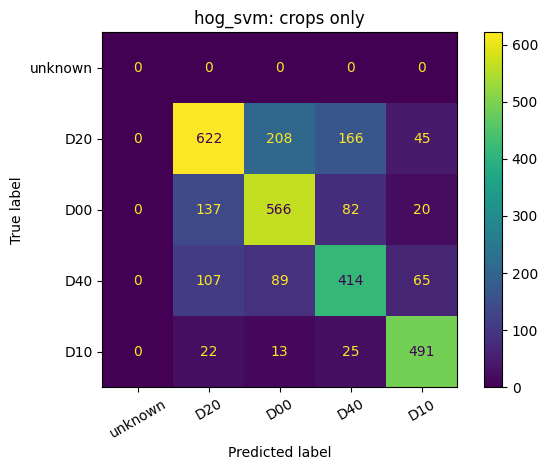

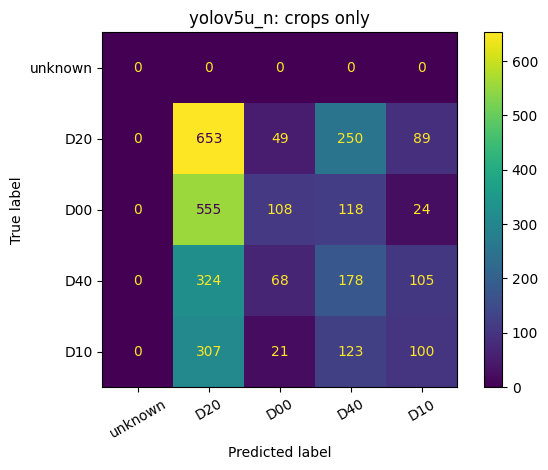

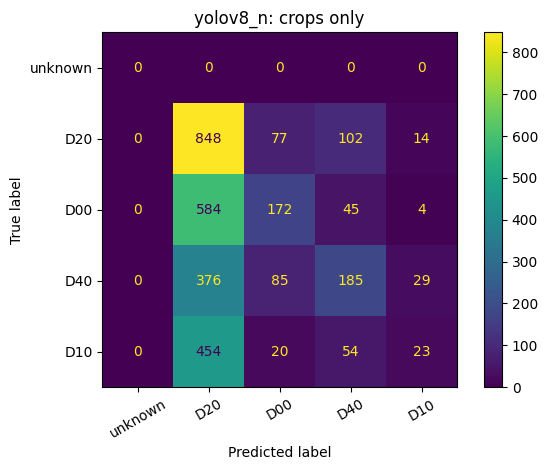

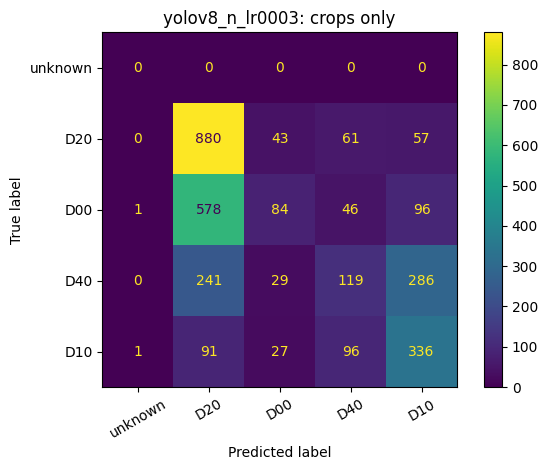

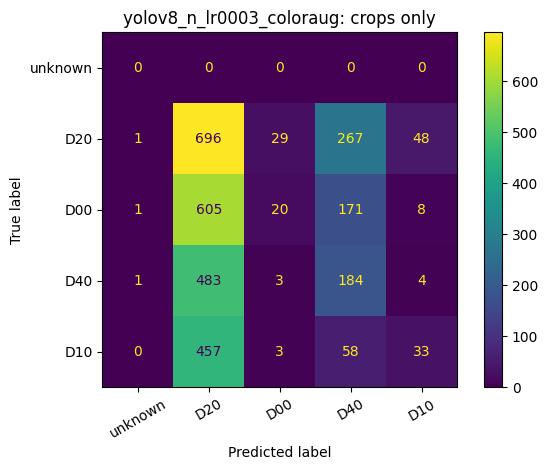

,model,task,accuracy,macro_f1,unknown_predictions
0,hog_svm,ground-truth crop classification,0.681315,0.691029,0
1,yolov5u_n,ground-truth crop classification,0.338216,0.288505,0
2,yolov8_n,ground-truth crop classification,0.399740,0.308270,0
3,yolov8_n_lr0003,ground-truth crop classification,0.461914,0.384308,2
4,yolov8_n_lr0003_coloraug,ground-truth crop classification,0.303711,0.211179,3


In [21]:
y_true=HOG_DATA['test'][1]
crop_results=[]
hog_pred=HOG_MODEL.predict(HOG_DATA['test'][0])
CROP_PREDICTIONS={'hog_svm':hog_pred}
for name,path in MODEL_PATHS.items():
    model=YOLO(str(path)); predicted=[]; pairs=crop_indices['test']
    for start in tqdm(range(0,len(pairs),32),desc=f'Crop classification {name}'):
        batch=[]
        for p,j in pairs[start:start+32]:
            with Image.open(p) as im:
                im=im.convert('RGB'); W,H=im.size; _,x,y,w,h=labels_by_path[p][j]
                box=(max(0,int(np.floor((x-w/2)*W))),max(0,int(np.floor((y-h/2)*H))),
                     min(W,int(np.ceil((x+w/2)*W))),min(H,int(np.ceil((y+h/2)*H))))
                batch.append(im.crop(box))
        results=model.predict(batch,imgsz=IMGSZ,conf=PRED_FLOOR,iou=NMS_IOU,device=DEVICE,verbose=False)
        for r in results:
            predicted.append(int(r.boxes.cls[r.boxes.conf.argmax()].item()) if len(r.boxes) else -1)
    CROP_PREDICTIONS[name]=np.asarray(predicted); del model
for name,pred in CROP_PREDICTIONS.items():
    report=classification_report(y_true,pred,labels=list(NAMES),target_names=list(NAMES.values()),
                                 output_dict=True,zero_division=0)
    (OUT/f'{name}_crop_report.json').write_text(json.dumps(report,indent=2))
    crop_results.append({'model':name,'task':'ground-truth crop classification',
       'accuracy':float(np.mean(y_true==pred)),
       'macro_f1':f1_score(y_true,pred,labels=list(NAMES),average='macro',zero_division=0),
       'unknown_predictions':int((pred==-1).sum())})
    ConfusionMatrixDisplay.from_predictions(y_true,pred,labels=[-1,*NAMES],
        display_labels=['unknown',*NAMES.values()],xticks_rotation=30)
    plt.title(f'{name}: crops only'); plt.tight_layout(); plt.savefig(OUT/f'{name}_crop_confusion.png'); plt.show()
crop_comparison=pd.DataFrame(crop_results); display(crop_comparison)
crop_comparison.to_csv(OUT/'crop_comparison.csv',index=False)


## 18 · Country-level evaluation

Supported filename prefixes identify country groups. This cell reports D40 recall at the frozen operating threshold and the number of ground-truth potholes per group. It also runs official mAP evaluation on each country's test-image list. A separate YAML points to each list without changing the main test split.

Unknown origin remains an explicit group. If all origins are unknown, overall evaluation remains possible but the charter's country-level evaluation requirement is pending until metadata is supplied. This analysis does not tune separate thresholds by country. Tiny samples or groups with no D40 objects do not support reliable conclusions about pothole recall. Country reports are saved as CSV.

If every test-image origin is unknown, this cell writes an empty country report and skips redundant inference. It does not present the overall test result as a country result.


In [22]:
if set(manifest.loc[manifest.split=='test','country']) <= {'unknown'}:
    country_report=pd.DataFrame(columns=['model','country','images','d40_recall','d40_precision','map50'])
    country_report.to_csv(OUT/'test_by_country.csv',index=False)
    print('Country evaluation unavailable: all test-image origins are unknown. No redundant inference was run.')
else:
    country_rows=[]
    for name,path in MODEL_PATHS.items():
        model=YOLO(str(path))
        for country,group in manifest.loc[manifest.split=='test'].groupby('country'):
            paths=group.path.tolist()
            table,_=score_predictions(TEST_PREDS[name],paths,SELECTED_THRESHOLDS[name])
            p=table.loc[table.class_id==POTHOLE_ID].iloc[0]
            list_path=ROOT/f'test_{country}.txt'; list_path.write_text('\n'.join(paths)+'\n')
            cfg=dict(runtime_config); cfg['test']=str(list_path)
            cfg_path=ROOT/f'data_{country}.yaml'; cfg_path.write_text(yaml.safe_dump(cfg))
            metrics=model.val(data=str(cfg_path),split='test',imgsz=IMGSZ,batch=BATCH,device=DEVICE,
                 conf=PRED_FLOOR,iou=NMS_IOU,plots=False,project=str(RUNS),name=f'{name}_{country}',exist_ok=True)
            country_rows.append({'model':name,'country':country,'images':len(paths),
                'd40_objects':int(p.support),'d40_recall':p.recall,'d40_precision':p.precision,
                'map50':float(metrics.box.map50),'map50_95':float(metrics.box.map)})
        del model
    country_report=pd.DataFrame(country_rows); display(country_report)
    country_report.to_csv(OUT/'test_by_country.csv',index=False)
    if set(manifest.country)=={'unknown'}:
        print('Country metadata unavailable: charter country-level evaluation remains pending.')


Country evaluation unavailable: all test-image origins are unknown. No redundant inference was run.


## 19 · Error analysis and missed-pothole examples

For the detector selected on validation, this cell displays up to six test images with the largest numbers of missed D40 objects. Each row compares ground-truth boxes with predictions above the frozen threshold.

Inspect small or occluded defects, shadows, road markings, blur, class confusion, and questionable annotations. The examples are deliberately selected for errors and are not representative of average performance. This analysis documents final-model limitations; improvements based on these test errors require a new evaluation round. The per-image FP/FN table also supports false-alarm inspection, beyond missed potholes alone.


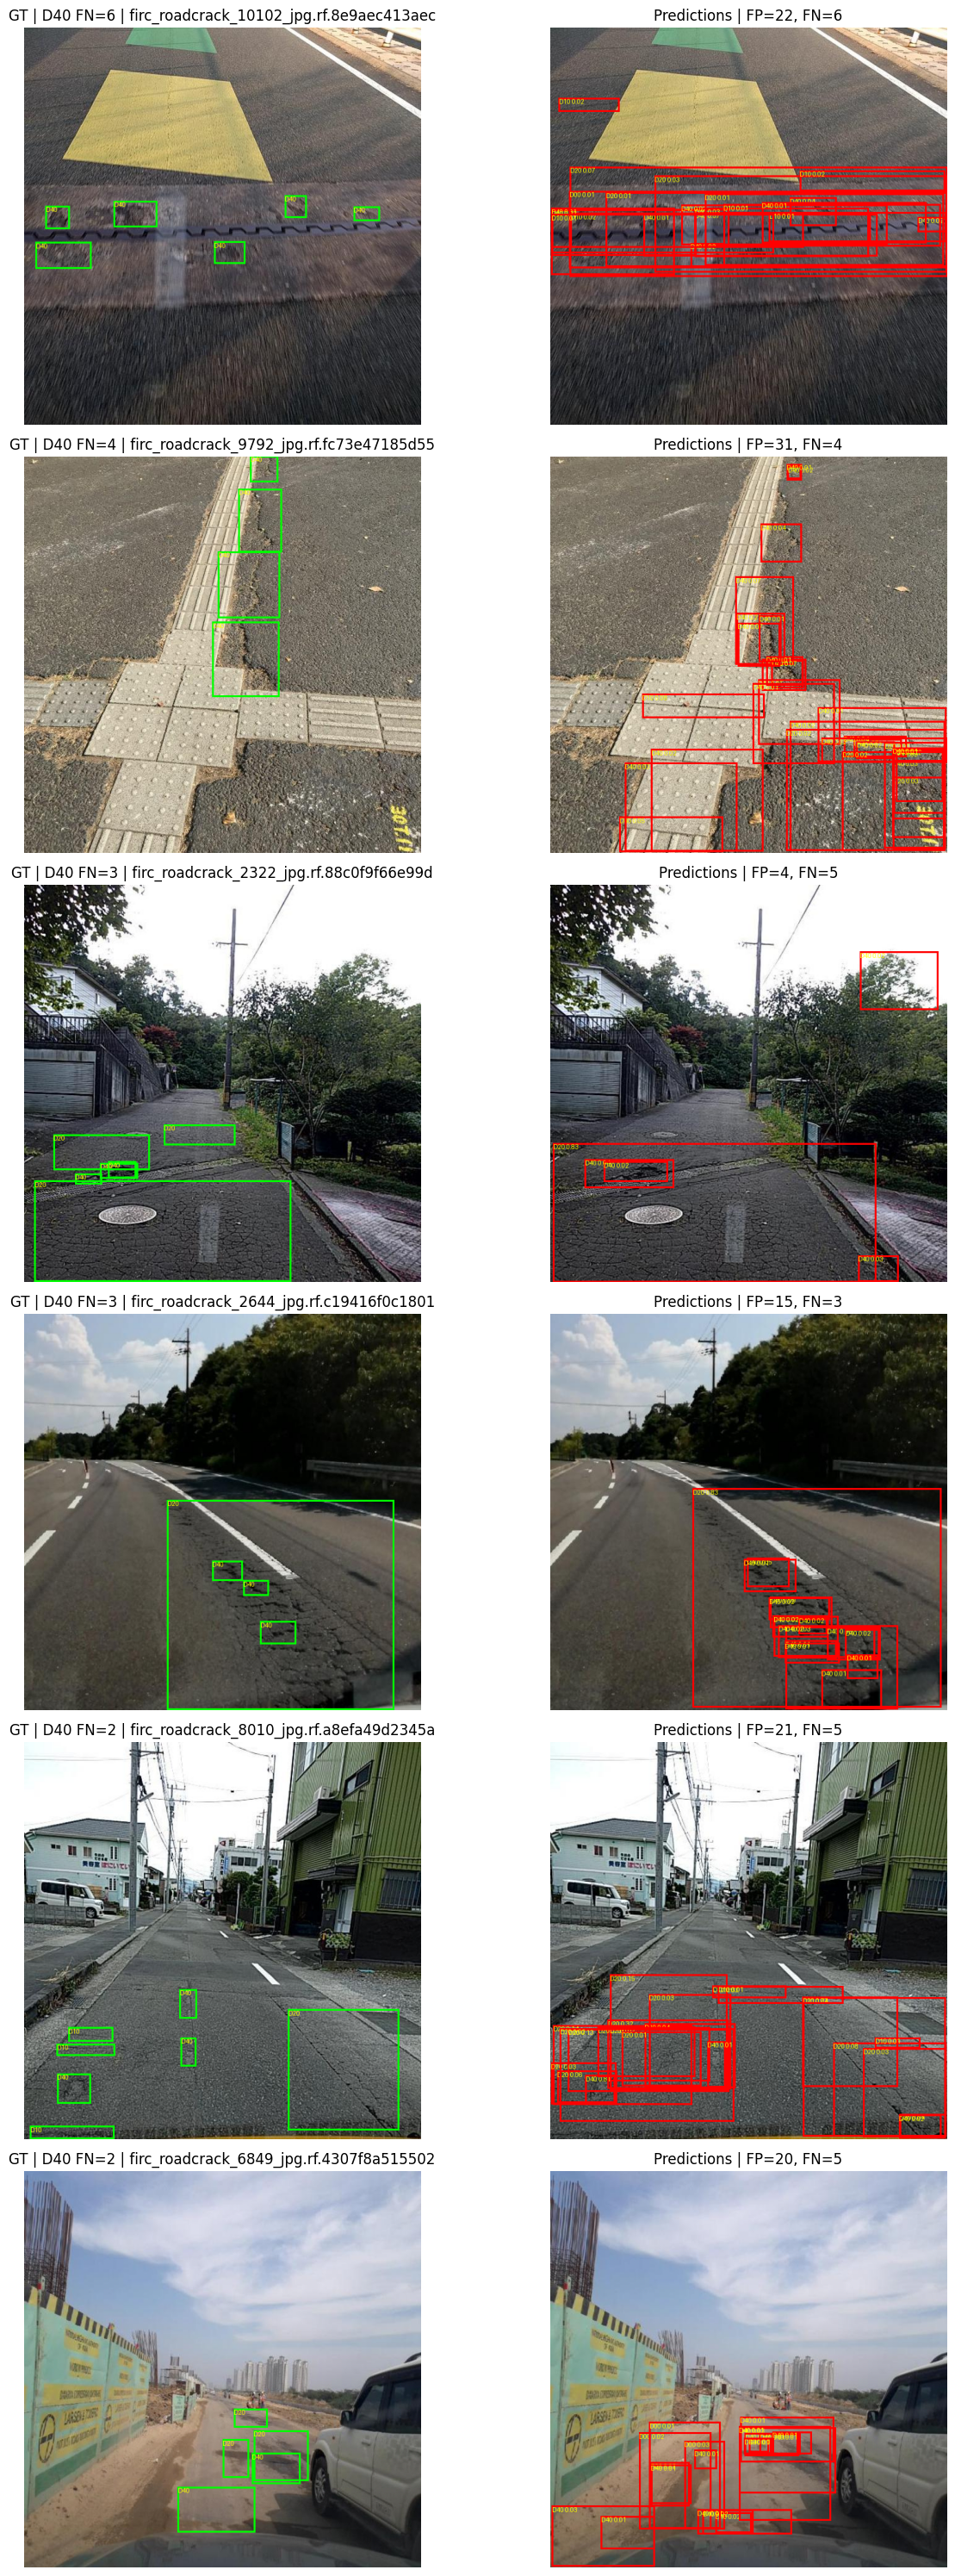

,path,country,tp,fp,fn,d40_fn
19,/content/roadguard/dataset_extracted/road_dama...,unknown,0,22,6,6
1467,/content/roadguard/dataset_extracted/road_dama...,unknown,0,31,4,4
461,/content/roadguard/dataset_extracted/road_dama...,unknown,1,4,5,3
512,/content/roadguard/dataset_extracted/road_dama...,unknown,1,15,3,3
1216,/content/roadguard/dataset_extracted/road_dama...,unknown,2,21,5,2
1041,/content/roadguard/dataset_extracted/road_dama...,unknown,0,20,5,2


In [23]:
worst=TEST_IMAGE_TABLES[CHOSEN_MODEL].sort_values(['d40_fn','fn','fp'],ascending=False).head(6)
fig,axes=plt.subplots(len(worst),2,figsize=(14,5*len(worst)),squeeze=False)
for row,(_,r) in enumerate(worst.iterrows()):
    pred=TEST_PREDS[CHOSEN_MODEL][r.path]
    pred=pred[pred[:,5]>=SELECTED_THRESHOLDS[CHOSEN_MODEL]]
    axes[row,0].imshow(draw_boxes(r.path,gt_xyxy(r.path)))
    axes[row,1].imshow(draw_boxes(r.path,pred,pred=True))
    axes[row,0].set_title(f'GT | D40 FN={r.d40_fn} | {Path(r.path).name[:40]}')
    axes[row,1].set_title(f'Predictions | FP={r.fp}, FN={r.fn}')
    for ax in axes[row]: ax.axis('off')
plt.tight_layout(); plt.savefig(OUT/'worst_d40_errors.png'); plt.show()
display(worst)


## 20 · Image-quality checks and the agent output contract

This cell defines a quality gate before inference: image readability, minimum resolution, mean brightness, and Laplacian variance as a blur heuristic. These are initial, uncalibrated rules. Passing them does not guarantee an in-domain image or a safe road.

The JSON output includes damage codes, confidence scores, pixel boxes, and relative image area. **Image area is not physical damage area, depth, or engineering severity.** Road type and lane obstruction are supplied as metadata, not inferred by the CV model.

Unreadable or poor-quality images, missing metadata, no detections, unverified class mapping, and an unconnected agent require human review. This notebook does not assign operational urgency, call an LLM, invent a retrieved source, or perform an external action. The team's agent component should consume this contract, retrieve a relevant procedure, and dynamically select tools. An example payload and the quality rules are saved.

The example uses a validation image. Every payload explicitly identifies this export as a research prototype requiring human review; the existing runs did not meet the charter targets. This interface performs no RAG or external actions.


In [24]:
QUALITY_RULES={'min_side':320,'min_laplacian_variance':40.0,'min_mean_gray':25.0,'max_mean_gray':235.0}
def check_image_quality(path):
    try:
        with Image.open(path) as im:
            rgb=np.asarray(ImageOps.exif_transpose(im).convert('RGB'))
        gray=cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)
        blur=float(cv2.Laplacian(gray,cv2.CV_64F).var()); light=float(gray.mean())
        reasons=[]
        if min(gray.shape)<QUALITY_RULES['min_side']: reasons.append('low_resolution')
        if blur<QUALITY_RULES['min_laplacian_variance']: reasons.append('possible_blur')
        if not QUALITY_RULES['min_mean_gray']<=light<=QUALITY_RULES['max_mean_gray']: reasons.append('extreme_brightness')
        return {'accepted':not reasons,'reasons':reasons,'laplacian_variance':blur,'mean_gray':light,
                'width':int(rgb.shape[1]),'height':int(rgb.shape[0])}
    except Exception as e:
        return {'accepted':False,'reasons':['unreadable_image'],'error_type':type(e).__name__}
DEPLOY_MODEL=YOLO(str(MODEL_PATHS[CHOSEN_MODEL]))
def analyze_for_agent(path,road_type=None,lane_obstructed=None):
    quality=check_image_quality(path)
    payload={'schema_version':'1.0','image_id':Path(path).name,'model':CHOSEN_MODEL,
       'threshold':SELECTED_THRESHOLDS[CHOSEN_MODEL],'mapping_verified':MAPPING_VERIFIED,
       'quality':quality,'metadata':{'road_type':road_type,'lane_obstructed':lane_obstructed},
       'detections':[],'recommended_action':None,'human_review_required':True,
       'deployment_status':'research_only_human_review',
       'agent_status':'not_connected','retrieved_sources':[], 'work_order_created':False}
    if quality['accepted']:
        with Image.open(path) as im: image=ImageOps.exif_transpose(im).convert('RGB')
        r=DEPLOY_MODEL.predict(image,imgsz=IMGSZ,conf=payload['threshold'],iou=NMS_IOU,device=DEVICE,verbose=False)[0]
        for box,conf,cid in zip(r.boxes.xyxy.cpu().numpy(),r.boxes.conf.cpu().numpy(),r.boxes.cls.cpu().numpy()):
            x1,y1,x2,y2=map(float,box)
            payload['detections'].append({'class_id':int(cid),'damage_code':NAMES[int(cid)],
               'confidence_score':float(conf),'bbox_xyxy_pixels':[x1,y1,x2,y2],
               'relative_image_area':(x2-x1)*(y2-y1)/(quality['width']*quality['height'])})
    payload['review_reasons']=['agent_not_connected','research_prototype_targets_not_met']
    if not quality['accepted']: payload['review_reasons'].append('insufficient_image_quality')
    if not payload['detections']: payload['review_reasons'].append('no_detection_does_not_mean_safe_road')
    if not MAPPING_VERIFIED: payload['review_reasons'].append('unverified_class_mapping')
    if road_type is None or lane_obstructed is None: payload['review_reasons'].append('missing_operational_metadata')
    return payload
(OUT/'quality_rules.json').write_text(json.dumps(QUALITY_RULES,indent=2))
# Demonstrate the interface on validation data; no test-based selection is made here.
example_path=manifest.loc[manifest.split=='val','path'].iloc[0]
example_payload=analyze_for_agent(example_path)
(OUT/'example_agent_payload.json').write_text(json.dumps(example_payload,indent=2))
print(json.dumps(example_payload,indent=2))


{
  "schema_version": "1.0",
  "image_id": "firc_roadcrack_10011_jpg.rf.8de53fdeefb5151a20a672e034dc2c15.jpg",
  "model": "yolov8_n_lr0003_coloraug",
  "threshold": 0.01,
  "mapping_verified": true,
  "quality": {
    "accepted": true,
    "reasons": [],
    "laplacian_variance": 2047.0276952825486,
    "mean_gray": 121.19399658203125,
    "width": 640,
    "height": 640
  },
  "metadata": {
    "road_type": null,
    "lane_obstructed": null
  },
  "detections": [
    {
      "class_id": 0,
      "damage_code": "D20",
      "confidence_score": 0.4094449281692505,
      "bbox_xyxy_pixels": [
        71.7121810913086,
        375.56884765625,
        272.2188415527344,
        615.54150390625
      ],
      "relative_image_area": 0.11747098610045213
    },
    {
      "class_id": 0,
      "damage_code": "D20",
      "confidence_score": 0.2173733115196228,
      "bbox_xyxy_pixels": [
        93.22589111328125,
        362.8929443359375,
        574.2130126953125,
        612.8504638671875

## 21 · Independent local field test — optional, never simulated

To evaluate transfer to Israel, provide 30–50 independent local images with YOLO annotations and the same class mapping. They must not have been used for training or threshold selection. Upload them through Colab's Files panel to `roadguard/field/images` and `roadguard/field/labels`; Drive is unnecessary.

If no images exist, this cell explicitly skips evaluation and generates no synthetic data or scores. Every image needs an annotation file, including an empty file for a manually verified background image. Exact file and pixel duplicates against existing splits are rejected; sequence independence also requires manual verification.

Only the frozen detector is evaluated, with the same threshold and matching IoU. Quality rejections are reported separately: detector evaluation still predicts all field images to measure the domain gap. Per-class results, errors, quality measurements, and official mAP are saved. Do not retrain on this held-out field set.


In [25]:
FIELD_STATUS='not_run'; FIELD_REPORT=None
field_images=sorted(p for p in (FIELD_ROOT/'images').glob('*') if p.suffix.lower() in EXTS)
if not field_images:
    print('Local field evaluation NOT RUN: upload independent local images and YOLO labels to FIELD_ROOT.')
else:
    if not 30<=len(field_images)<=50: print('Charter expects 30–50 images; current N=',len(field_images))
    known_hashes=set(manifest.sha256); known_pixels=set(manifest.pixel_hash)
    field_records=[]
    for p in field_images:
        lab=FIELD_ROOT/'labels'/f'{p.stem}.txt'
        if not lab.exists(): raise FileNotFoundError(f'Missing field annotation: {lab}')
        a=read_yolo(lab)
        with Image.open(p) as im: rgb=np.asarray(im.convert('RGB')); H,W=rgb.shape[:2]
        px=hashlib.sha256(str(rgb.shape).encode()+rgb.tobytes()).hexdigest()
        if sha256_file(p) in known_hashes or px in known_pixels: raise ValueError(f'Field leakage: {p}')
        labels_by_path[str(p)]=a
        field_records.append({'path':str(p),'width':W,'height':H,'country':'Israel','split':'field'})
    # gt_xyxy uses the manifest for dimensions. Add independent field rows after training/evaluation only.
    manifest=pd.concat([manifest.loc[manifest.split!='field'],pd.DataFrame(field_records)],ignore_index=True)
    field_preds=predict_paths(DEPLOY_MODEL,[str(p) for p in field_images])
    FIELD_REPORT,field_errors=score_predictions(field_preds,[str(p) for p in field_images],SELECTED_THRESHOLDS[CHOSEN_MODEL])
    field_list=ROOT/'field_images.txt'; field_list.write_text('\n'.join(str(p) for p in field_images)+'\n')
    field_cfg=dict(runtime_config); field_cfg['test']=str(field_list)
    field_yaml=ROOT/'field.yaml'; field_yaml.write_text(yaml.safe_dump(field_cfg))
    field_metrics=DEPLOY_MODEL.val(data=str(field_yaml),split='test',imgsz=IMGSZ,batch=BATCH,device=DEVICE,
        conf=PRED_FLOOR,iou=NMS_IOU,project=str(RUNS),name='local_field',plots=True,exist_ok=True)
    FIELD_REPORT.to_csv(OUT/'field_per_class.csv',index=False)
    field_errors.to_csv(OUT/'field_per_image.csv',index=False)
    qualities=[{'image':p.name,**check_image_quality(p)} for p in field_images]
    pd.DataFrame(qualities).to_csv(OUT/'field_quality.csv',index=False)
    FIELD_STATUS='evaluated'
    display(FIELD_REPORT)
    print('Field mAP50:',field_metrics.box.map50,'| Internal test mAP50:',
          summary.loc[summary.model==CHOSEN_MODEL,'map50'].iloc[0])
(OUT/'field_status.json').write_text(json.dumps({'status':FIELD_STATUS,'n_images':len(field_images)},indent=2))


Local field evaluation NOT RUN: upload independent local images and YOLO labels to FIELD_ROOT.


42

## 22 · Summary, Model Card, and agent integration protocol

This cell generates an English Markdown report using actual execution results, the archive hash and source commit, class-mapping status, split limitations, and field-test status. Agent metrics remain pending: without the corpus, agent, and reference-labelled scenarios, decision accuracy and groundedness cannot be measured.

For 50 scenarios, the 85% decision target requires at least 43 correct decisions. Groundedness needs a denominator defined in advance; the suggested protocol uses explanations that require a source and requires at least 90% to be supported by retrieved passages. Sources must retain issuing body, date, applicable conditions, and a link. A fixed rule chain must not be represented as a working agent.

The 72-to-4-hour response target and 35% contractor savings remain future pilot objectives. Image datasets alone cannot measure them. The report also documents intended use, limitations, fallback scope, monitoring, and the need for a fresh held-out evaluation after development changes.


**Documentation correction:** This cell now sets mapping provenance explicitly before generating the model card. The retained output was printed before that wording correction; numerical results are unchanged. Section 22b in the executed session updated the saved report and mapping JSON before export.

In [ ]:
MAPPING_STATUS = ('Original Roboflow YAML supplied by user; '
                  'repository preprocessing preserves numeric class IDs.')
selected_result=summary.loc[summary.model==CHOSEN_MODEL].iloc[0].to_dict()
card=f"""# RoadGuard — CV Model Card

## Intended use
Human decision support for municipal road-hazard image triage. Not engineering certification,
depth estimation, physical damage measurement, or autonomous road closure/dispatch.

## Data and provenance
- Repository: {REPO_URL}
- Commit: {REPO_COMMIT}
- Processed archive: {DATA_URL}
- Archive SHA256: {ARCHIVE_SHA256}
- Upstream project: https://universe.roboflow.com/xjsj/road-damage-10k/dataset/1
- Team-processed archive; do not identify it as canonical RDD2020/RDD2022 without evidence.
- Original YAML names: {ORIGINAL_NAMES}
- Used semantic mapping: {NAMES}
- Mapping status: {MAPPING_STATUS}
- Source listing: CC BY 4.0. Retain source attribution; verify derivative/weight redistribution rights separately.
- Original source YAML class order: AlligatorCrack, LongitudinalCracks, Potholes, TransverseCrack.

## Protocol
Preserved the prepared split. HOG-SVM uses training-only scaling and validation-only C selection.
Detectors use pretrained weights, AdamW, shared data/seed/budget, existing offline augmentation,
early stopping, and validation-only model/threshold selection.
The test set was inspected during development. Results are retrospective results on an exposed test set; no more tuning is authorized by this protocol. A changed model requires fresh independent evaluation.
File hashes, decoded-pixel hashes, and normalized original names were checked across splits.
Original camera-sequence IDs are unavailable: neighboring-frame leakage is NOT ruled out.
YOLOv5nu denotes Ultralytics YOLOv5u rather than original anchor-based YOLOv5.

## Frozen research candidate — human review required
{json.dumps(LOCK,indent=2)}

## Final test detection result
{json.dumps(selected_result,indent=2,default=str)}
All detector results: test_detection_summary.csv; per-class and country CSVs are separate.
Crop classification results are a distinct oracle-localization diagnostic, not detection mAP.

## Domain gap and limitations
Field evaluation: {FIELD_STATUS}, N={len(field_images)}.
No detections do not establish that a road is safe. Small/occluded defects, shadows, markings,
image quality, country/domain differences and annotation errors can affect performance.
Bounding-box area is a fraction of image pixels, not physical area or engineering severity.
Quality heuristics are not calibrated; confidence scores are not calibrated probabilities.
Targets are not accepted as semantically verified unless the class mapping is verified.

## Agent integration — pending team component
Input contract: example_agent_payload.json. Outputs remain human-review cases until an agent is connected.
Provide official guidance passages with issuing body, date, hazard type, triggering conditions and URL.
Clearly label international manuals as non-binding in Israel when applicable.
Implement and evaluate the charter tools: check_hazard_severity, query_repair_standards,
request_additional_evidence, create_draft_work_order and flag_for_urgent_review.
The severity tool computes transparent operational priority, not engineering severity.
The agent dynamically selects tools and uses image quality, metadata, CV and retrieved guidance.
If quality/confidence is insufficient, no supporting procedure is found, metadata is missing,
or a tool fails: no work order; request evidence or transfer to human review.
All external municipal/map/contractor connections must remain mocked in the course project.

## Agent evaluation protocol — not executed
Use 50 held-out, independently labelled scenarios covering potholes, cracks, poor images,
missing metadata, low-confidence/ambiguous findings, missing sources and tool failures.
Reference actions: urgent inspection / standard queue / request evidence / human review.
At least 43/50 correct decisions meets the 85% target.
For source-requiring explanations, at least 90% must be supported by the retrieved passages;
record supporting passage IDs and assess correctness of the claim-source relationship.
Also record unsupported claims and unsafe-action attempts. Report denominators and scenario results.
No synthetic scores or success claims are supplied here.

## Operational targets and next steps
72h to 4h response time and 35% contractor savings require a real pilot with operational data.
The source mapping has been corrected using original YAML and ID-preserving preprocessing. Resolve remaining provenance/licensing and sequence limitations; complete independent local testing. No additional training is needed to document this project phase.
If four-class deployment is not viable, the charter allows a separately evaluated D20/D40 cut-down version;
this notebook does not silently drop classes or reuse four-class metrics for that version.
Monitor recall/precision on labelled audits, domain/quality drift, field error types and review volume.
Retrain only with a versioned dataset and a fresh held-out evaluation protocol.
"""
(OUT/'MODEL_CARD.md').write_text(card)
print(card)


# RoadGuard — CV Model Card

## Intended use
Human decision support for municipal road-hazard image triage. Not engineering certification,
depth estimation, physical damage measurement, or autonomous road closure/dispatch.

## Data and provenance
- Repository: https://github.com/shaisadeh/Final-Project-DS.git
- Commit: 05b9d4f4fac4c5fb2c53fb0a6e443bb5412e7bfe
- Processed archive: https://drive.google.com/file/d/1xzHdXoXc4NPibka0KG9GAqq_EfdTUulo/view?usp=sharing
- Archive SHA256: 9551c4a5d43cdd9a100796d58476c7245e635174be57870e10439104c7bab84c
- Upstream project: https://universe.roboflow.com/xjsj/road-damage-10k/dataset/1
- Team-processed archive; do not identify it as canonical RDD2020/RDD2022 without evidence.
- Original YAML names: {0: 'Class_0', 1: 'Class_1', 2: 'Class_2', 3: 'Class_3'}
- Used semantic mapping: {0: 'D20', 1: 'D00', 2: 'D40', 3: 'D10'}
- Mapping status: Data Lead confirmed
- Source listing: CC BY 4.0. Retain source attribution; verify derivative/weight redistributio

## 22a · Install ONNX export and CPU verification dependencies

This cell installs ONNX model-format support, ONNX Runtime for CPU numerical verification, and ONNX Script used by modern PyTorch export. It does not install a different Ultralytics or PyTorch version, reset variables or train a model. Let installation finish before the next cell. CPU verification avoids consuming GPU training time.


In [27]:
%pip -q install "onnx>=1.16,<2" "onnxruntime>=1.18,<2" "onnxscript>=0.3,<1"

## 22b · Export the frozen candidate, adapt class channels, and write test CSV

The cell requires the active session's models, test prediction cache, audited manifest and section 22 report. It first corrects the mapping-provenance wording in the report and mapping JSON. It copies the chosen trusted checkpoint to a temporary export folder and exports the same trained YOLOv8n as static float32 ONNX, 640x640, batch 1, opset 12, without embedded NMS.

**Class order is adapted in the graph itself.** The trained model uses 0=D20, 1=D00, 2=D40, 3=D10. The webapp requires 0=D00, 1=D10, 2=D20, 3=D40. A Gather node reorders the four score channels while preserving the four box channels. Model metadata is also updated. Native checkpoint names, labels, parameters and all prior metrics remain unchanged. The cell verifies ONNX structure, input/output layout, opset and the strict 20 MB limit. It stops if a requirement fails; it does not quantize or retrain automatically.

Up to three validation images are letterboxed and used to compare native ONNX predictions numerically with PyTorch, then compare the adapted ONNX output against the exact expected score permutation. This is a conversion smoke check, not new model selection or full browser validation. Browser preprocessing must preserve aspect ratio with padding; plain stretched resize does not reproduce the documented evaluation pipeline.

The CSV has exactly the requested six columns, one row per test image and unique filename IDs. It reuses the selected model's cached test detections, retains its frozen confidence threshold and selects the highest-confidence retained detection across all classes. It uses colon-separated xyxy original-image pixel boxes, matching the teammate's example rows. With no retained detection, class and bbox are blank and confidence is 0.0; the image is retained, not silently dropped or assigned a fake class. The README documents this missing-evidence case and the agent must handle it. A top1 CSV is a lossy agent-evaluation input, not a substitute for full detection metrics.

The resulting ZIP contains the requested ONNX and CSV at the requested paths, plus an English integration README and machine-readable contract with checksums, preprocessing, postprocessing, mappings, thresholds and checks. The export is explicitly marked as a research prototype requiring human review. Browser loading/decoding and full ONNX test inference remain unverified until actually performed. After download, run original section 23 as well and save the active notebook.


In [28]:

from pathlib import Path
import ast, csv, hashlib, importlib.metadata, json, shutil
import numpy as np
import pandas as pd
import onnx
import onnxruntime as ort
from onnx import helper, numpy_helper
from PIL import Image, ImageOps
import torch
from ultralytics import YOLO
from ultralytics.data.augment import LetterBox

# This cell runs in the existing modeling notebook, after section 22.
required=['OUT','ROOT','MODEL_PATHS','CHOSEN_MODEL','SELECTED_THRESHOLDS',
          'TEST_PREDS','TEST_PATHS','manifest','NAMES','NMS_IOU','MAPPING_VERIFIED']
missing=[name for name in required if name not in globals()]
if missing:
    raise RuntimeError('Use the active modeling session; missing variables: '+', '.join(missing))
native_names={0:'D20',1:'D00',2:'D40',3:'D10'}
web_names={0:'D00',1:'D10',2:'D20',3:'D40'}
if NAMES!=native_names or not MAPPING_VERIFIED:
    raise ValueError('Verified native mapping is required; do not change NAMES to the webapp order.')
if not CHOSEN_MODEL.startswith('yolov8_n'):
    raise ValueError('The webapp contract accepts the frozen YOLOv8n candidate only.')
if CHOSEN_MODEL not in TEST_PREDS:
    raise ValueError('Cached test predictions for the selected model are missing.')

# Correct provenance in saved reports; this changes no labels, parameters or metrics.
MAPPING_STATUS=('Original Roboflow YAML supplied by user; '
                'repository preprocessing preserves numeric class IDs.')
card_path=OUT/'MODEL_CARD.md'
if not card_path.is_file(): raise FileNotFoundError('Run section 22 first.')
card_path.write_text(card_path.read_text().replace(
    '- Mapping status: Data Lead confirmed', '- Mapping status: '+MAPPING_STATUS))
mapping_path=OUT/'class_mapping.json'
info=json.loads(mapping_path.read_text()); info['status']=MAPPING_STATUS
mapping_path.write_text(json.dumps(info,indent=2))

# Isolate the webapp ID contract from the native PyTorch/checkpoint contract.
handoff=OUT/'agent_webapp_handoff'
model_dir=handoff/'webapp/assets/models'; model_dir.mkdir(parents=True,exist_ok=True)
csv_dir=handoff/'data/batch_eval'; csv_dir.mkdir(parents=True,exist_ok=True)
export_work=ROOT/'onnx_export_work'; export_work.mkdir(exist_ok=True)
source=Path(MODEL_PATHS[CHOSEN_MODEL])
trusted_copy=export_work/'selected_native.pt'
shutil.copy2(source,trusted_copy)
export_model=YOLO(str(trusted_copy))
if getattr(export_model.model.model[-1],'nc',None)!=4:
    raise ValueError('Expected a four-class detection head.')
export_model.model.names=native_names.copy()
print('Exporting frozen candidate:',CHOSEN_MODEL,'— no training')
native_onnx=Path(export_model.export(format='onnx',imgsz=640,batch=1,
    opset=12,device='cpu',half=False,dynamic=False,simplify=False,nms=False))
graph=onnx.load(str(native_onnx))
onnx.checker.check_model(graph)
if len(graph.graph.input)!=1 or len(graph.graph.output)!=1:
    raise ValueError('Expected one image input and one raw detection output.')
input_shape=[d.dim_value for d in graph.graph.input[0].type.tensor_type.shape.dim]
output_shape=[d.dim_value for d in graph.graph.output[0].type.tensor_type.shape.dim]
if input_shape!=[1,3,640,640] or len(output_shape)!=3 or output_shape[1]!=8:
    raise ValueError(f'Unexpected tensor layout: {input_shape} -> {output_shape}')

# YOLOv8 raw output: [cx,cy,w,h, score_native_0,...,score_native_3].
# Reorder actual class-score channels: D00=native1, D10=native3,
# D20=native0, D40=native2. Renaming metadata alone would be incorrect.
channel_order=np.asarray([0,1,2,3,5,7,4,6],dtype=np.int64)
indices_name='roadguard_webapp_channel_order'
new_output='roadguard_webapp_output'
existing={v.name for v in graph.graph.initializer}
existing.update(x for node in graph.graph.node for x in [*node.input,*node.output])
if indices_name in existing or new_output in existing:
    raise ValueError('Unexpected graph-name collision.')
old_output=graph.graph.output[0].name
graph.graph.initializer.append(numpy_helper.from_array(channel_order,name=indices_name))
graph.graph.node.append(helper.make_node('Gather',[old_output,indices_name],[new_output],axis=1,
                                         name='RoadGuardReorderClassScores'))
graph.graph.output[0].name=new_output
metadata={p.key:p.value for p in graph.metadata_props}
metadata.update({'names':str(web_names),'roadguard_native_names':json.dumps(native_names),
                 'roadguard_class_order':'D00,D10,D20,D40',
                 'roadguard_deployment_status':'research_only_human_review'})
helper.set_model_props(graph,metadata)
destination=model_dir/'yolov8n-roadguard.onnx'
onnx.checker.check_model(graph); onnx.save(graph,str(destination))
if destination.stat().st_size>=20_000_000:
    raise ValueError('ONNX exceeds the strict 20 MB limit. Do not quantize silently; investigate first.')
if min(v.version for v in graph.opset_import if v.domain in ('','ai.onnx'))<11:
    raise ValueError('ONNX opset is below the webapp minimum.')

# Numerical smoke check on up to three validation images, never model selection.
# Verify native ONNX against PyTorch and remapped ONNX against native outputs.
options=ort.SessionOptions(); options.intra_op_num_threads=2
native_session=ort.InferenceSession(str(native_onnx),sess_options=options,providers=['CPUExecutionProvider'])
web_session=ort.InferenceSession(str(destination),sess_options=options,providers=['CPUExecutionProvider'])
reference=YOLO(str(source)).model.cpu().float().eval()
sample=manifest.loc[manifest.split=='val','path'].head(3).tolist()
if not sample: raise ValueError('Validation images are needed for the conversion smoke check.')
checks=[]
for path in sample:
    with Image.open(path) as image:
        rgb=np.asarray(ImageOps.exif_transpose(image).convert('RGB'))
    padded=LetterBox(new_shape=(640,640),auto=False,stride=32)(image=rgb)
    tensor=np.ascontiguousarray(padded.transpose(2,0,1)[None],dtype=np.float32)/255.0
    with torch.inference_mode():
        raw=reference(torch.from_numpy(tensor))
        if isinstance(raw,(tuple,list)): raw=raw[0]
        raw=raw.detach().cpu().numpy()
    native=native_session.run(None,{native_session.get_inputs()[0].name:tensor})[0]
    remapped=web_session.run(None,{web_session.get_inputs()[0].name:tensor})[0]
    np.testing.assert_allclose(native,raw,rtol=1e-3,atol=1e-3,
                               err_msg='PyTorch/ONNX conversion mismatch')
    np.testing.assert_allclose(remapped,native[:,channel_order,:],rtol=1e-6,atol=1e-6,
                               err_msg='Webapp class-score reordering mismatch')
    checks.append({'image_id':Path(path).name,'pytorch_onnx_max_abs_error':float(np.max(np.abs(raw-native))),
                   'reorder_max_abs_error':float(np.max(np.abs(remapped-native[:,channel_order,:])))})
del reference, native_session, web_session

# One row per test image. Select highest-confidence detection after the frozen
# confidence filter and the original class-aware NMS used for TEST_PREDS.
# This reuses cached predictions; it does not rerun or tune test inference.
threshold=float(SELECTED_THRESHOLDS[CHOSEN_MODEL])
test_paths=[str(p) for p in TEST_PATHS]
expected_paths=manifest.loc[manifest.split=='test','path'].astype(str).tolist()
if set(test_paths)!=set(expected_paths) or len(test_paths)!=len(expected_paths):
    raise ValueError('Test-path registry does not match the audited manifest.')
image_ids=[Path(p).name for p in test_paths]
if len(set(image_ids))!=len(image_ids): raise ValueError('Duplicate image_id would break the agent join.')
dimensions=manifest.loc[manifest.split=='test'].set_index('path')
rows=[]; no_detection=[]
for path in test_paths:
    if path not in TEST_PREDS[CHOSEN_MODEL]: raise KeyError('Missing cached prediction: '+path)
    pred=np.asarray(TEST_PREDS[CHOSEN_MODEL][path])
    if pred.ndim!=2 or pred.shape[1]!=6: raise ValueError('Expected [class,x1,y1,x2,y2,confidence].')
    pred=pred[pred[:,5]>=threshold]
    width=int(dimensions.loc[path,'width']); height=int(dimensions.loc[path,'height'])
    row={'image_id':Path(path).name,'top1_class':'','top1_confidence':0.0,
         'bbox':'','image_width':width,'image_height':height}
    if len(pred):
        best=pred[int(np.argmax(pred[:,5]))]
        cid=int(best[0]); confidence=float(best[5]); box=best[1:5].astype(float)
        if cid not in native_names or not np.isfinite(best).all() or not 0<=confidence<=1:
            raise ValueError('Invalid cached detection.')
        box[[0,2]]=np.clip(box[[0,2]],0,width)
        box[[1,3]]=np.clip(box[[1,3]],0,height)
        if box[2]<=box[0] or box[3]<=box[1]: raise ValueError('Degenerate top1 box.')
        row.update(top1_class=native_names[cid],top1_confidence=confidence,
                   bbox=':'.join(f'{v:.6f}' for v in box))
    else:
        no_detection.append(row['image_id'])
    rows.append(row)
columns=['image_id','top1_class','top1_confidence','bbox','image_width','image_height']
csv_path=csv_dir/'yolo_predictions.csv'
with csv_path.open('w',newline='',encoding='utf-8') as f:
    writer=csv.DictWriter(f,fieldnames=columns); writer.writeheader(); writer.writerows(rows)
with csv_path.open(newline='',encoding='utf-8') as f:
    reader=csv.DictReader(f); reread=list(reader)
    assert reader.fieldnames==columns and len(reread)==len(test_paths)
    assert {r['image_id'] for r in reread}==set(image_ids)

contract={
 'schema_version':'1.0','selected_model':CHOSEN_MODEL,
 'deployment_status':'research_only_human_review',
 'onnx_class_ids':web_names,'native_checkpoint_class_ids':native_names,
 'onnx_input':{'shape':[1,3,640,640],'dtype':'float32','color':'RGB','layout':'NCHW',
               'normalization':'divide by 255','resize':'aspect-preserving letterbox; pad 114'},
 'onnx_output':{'shape':output_shape,'layout':'batch,channels,candidates',
                'channels':['center_x','center_y','width','height','D00','D10','D20','D40'],
                'box_units':'pixels in the 640x640 letterboxed input','nms_embedded':False,
                'scores':'per-class scores; no separate objectness channel; no additional sigmoid'},
 'postprocess':{'confidence_threshold':threshold,'class_aware_nms_iou':float(NMS_IOU),
                'max_detections':300,'map_boxes_back':'remove padding, divide by resize scale, clip to original image'},
 'csv':{'rows':len(rows),'columns':columns,'bbox_separator':':',
        'bbox_order':'x1:y1:x2:y2','box_units':'original-image pixels',
        'top1':'highest confidence across all classes after frozen threshold and NMS',
        'no_detection':{'top1_class':'','top1_confidence':0.0,'bbox':''},
        'no_detection_count':len(no_detection),'no_detection_image_ids':no_detection,
        'source':'cached selected-model PyTorch test predictions, not a new full ONNX test evaluation'},
 'checks':checks,'browser_runtime_tested':False,
 'versions':{name:importlib.metadata.version(name) for name in ['ultralytics','torch','onnx','onnxruntime']},
 'sha256':{str(p.relative_to(handoff)):hashlib.sha256(p.read_bytes()).hexdigest()
           for p in [destination,csv_path]},
}
(handoff/'handoff_contract.json').write_text(json.dumps(contract,indent=2))
readme='''# RoadGuard — webapp/agent handoff

Required paths:
- webapp/assets/models/yolov8n-roadguard.onnx
- data/batch_eval/yolo_predictions.csv

This is the frozen validation-selected YOLOv8n color-augmentation experiment. No new training was performed. The exported ONNX graph reorders actual class-score channels to 0=D00, 1=D10, 2=D20, 3=D40. The native PyTorch checkpoints retain 0=D20, 1=D00, 2=D40, 3=D10. Do not apply another class-order permutation in the browser.

Input: float32 RGB NCHW [1,3,640,640], divided by 255. Preserve aspect ratio using letterbox padding with value 114, not a stretched resize. Raw output: [1,8,8400] for the standard 640 YOLOv8n graph; read the actual shape in handoff_contract.json. Channels are cx,cy,w,h,D00,D10,D20,D40. There is no separate objectness channel; do not apply another sigmoid. Implement confidence filtering and class-aware NMS externally. Remove padding and undo the resize scale for original-image xyxy pixel boxes. Frozen confidence and NMS parameters are in handoff_contract.json. The model is float32, static batch 1, without embedded NMS.

CSV uses the requested six columns and one row per test image. bbox uses COLONS, following the two supplied example rows (the prose specification instead mentioned commas). Boxes refer to original image pixels. top1 is the highest-confidence retained detection across all four classes, not necessarily a pothole. Multiple detections are intentionally reduced to one; this CSV cannot reproduce full detection mAP or pothole recall. Use the per-detection/per-class evaluation reports in the full results ZIP for those metrics.

No-detection rows are retained with blank top1_class, blank bbox, confidence 0.0. Treat these as missing visual evidence requiring review; do not assign a fake damage class or zero-size box, and do not interpret them as a safe road. Check the count in handoff_contract.json. The agent must skip area_ratio calculation for blank boxes.

Conversion checks compare PyTorch vs native ONNX and verify the actual output permutation on up to three validation images. The CSV reuses completed PyTorch test inference. This is not a full ONNX evaluation or an onnxruntime-web browser test. Match the documented preprocessing/postprocessing and test browser loading on sample images before integration is accepted.

Research prototype: test D40 recall 0.7941, precision 0.0438, overall mAP50 0.3778 at threshold 0.01; both charter targets failed. Every result requires human review. Model scores are not calibrated probabilities, bbox area is not physical damage severity, and no autonomous work orders or road closures are authorized. Field and agent evaluation remain pending. A connected agent does not remove the CV limitations.
'''
(handoff/'README_HANDOFF.md').write_text(readme)
ZIP=Path(shutil.make_archive(str(ROOT/'RoadGuard_Agent_Webapp_Handoff'),'zip',root_dir=handoff))
print('ONNX ready:',destination,'| decimal MB:',round(destination.stat().st_size/1_000_000,2))
print('CSV ready:',csv_path,'| rows:',len(rows),'| no detection:',len(no_detection))
print('Class IDs in ONNX:',web_names)
print('Conversion and channel-reordering smoke checks passed on',len(checks),'validation images.')
print('Browser integration is not yet tested. ZIP:',ZIP)
try:
    from google.colab import files
    files.download(str(ZIP))
except ImportError:
    print('Download the handoff ZIP from this environment file browser.')


Exporting frozen candidate: yolov8_n_lr0003_coloraug — no training
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
WARNING ⚠️ This model has no one-to-one head; using one-to-many outputs.
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/content/roadguard/onnx_export_work/selected_native.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 8, 8400) (6.2 MB)

ONNX: starting export with onnx 1.23.2 opset 12...
ONNX: export success ✅ 0.9s, saved as '/content/roadguard/onnx_export_work/selected_native.onnx' (12.2 MB)

Export complete (1.2s)
Results saved to /content/roadguard/onnx_export_work/selected_native.onnx
Predict:         yolo predict task=detect 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 23 · Save trained artifacts and download a results ZIP

For each detector, this cell copies best.pt, last.pt, results.csv, args.yaml, completion metadata, training plots, and evaluation figures. `requirements.freeze.txt` records the packages actually installed. Reports, the baseline model, provenance, mappings, thresholds, and settings are included in the output directory.

The results ZIP excludes dataset images and the downloaded source archive, avoiding unnecessary copies and redistribution without verified licensing. In Colab, the ZIP is downloaded to the runner's computer. Download promptly because runtime storage is temporary; large ZIPs may be easier to retrieve from the Files panel. Saving the notebook itself does not preserve trained weights.

The ZIP also contains `roadguard_inference.py`, `inference_config.json`, minimal inference requirements, a checksum manifest and `README_HANDOFF.md`. The teammate can analyze new images without the dataset or a Drive connection. The export requires all four completed experiments and the preceding reports. It corrects checkpoint class-name metadata on exported copies; numeric model parameters and labels are unchanged. It does not retrain a detector.


In [29]:
expected={'yolov5u_n','yolov8_n','yolov8_n_lr0003','yolov8_n_lr0003_coloraug'}
missing=expected-set(MODEL_PATHS)
if missing: raise RuntimeError(f'Restore the missing completed experiments before export: {sorted(missing)}')
if CHOSEN_MODEL not in MODEL_PATHS: raise RuntimeError('Selected checkpoint is not registered')
for name,best in MODEL_PATHS.items():
    dest=OUT/'models'/name; dest.mkdir(parents=True,exist_ok=True)
    for filename in ['best.pt','last.pt']:
        p=best.parent/filename
        if p.exists(): shutil.copy2(p,dest/filename)
    run=RUNS/name
    for filename in ['results.csv','args.yaml','roadguard_complete.json']:
        p=run/filename
        if p.exists(): shutil.copy2(p,dest/filename)
    for p in run.glob('*.png'): shutil.copy2(p,dest/p.name)
    for eval_dir in RUNS.glob(f'{name}_*'):
        if eval_dir.is_dir():
            for p in eval_dir.glob('*.png'):
                target=OUT/'evaluation_plots'/eval_dir.name; target.mkdir(parents=True,exist_ok=True)
                shutil.copy2(p,target/p.name)
if (RUNS/'local_field').exists():
    shutil.copytree(RUNS/'local_field',OUT/'local_field_evaluation',dirs_exist_ok=True)
(OUT/'requirements.freeze.txt').write_text(subprocess.check_output([sys.executable,'-m','pip','freeze'],text=True))
(OUT/'run_settings.json').write_text(json.dumps({'seed':SEED,'imgsz':IMGSZ,'batch':BATCH,
    'epochs':EPOCHS,'patience':PATIENCE,'quality_rules':QUALITY_RULES,'lock':LOCK},indent=2))

(OUT/'roadguard_inference.py').write_text('"""RoadGuard research inference. No dataset or Drive mount is needed.\nUse only trusted team checkpoints. Every result requires human review.\n"""\nfrom pathlib import Path\nimport json\nimport hashlib\nimport numpy as np\nimport cv2\nfrom PIL import Image, ImageOps\nfrom ultralytics import YOLO\n\ndef load_bundle(bundle_dir, device=\'cpu\'):\n    global DEPLOY_MODEL, CHOSEN_MODEL, SELECTED_THRESHOLDS, NAMES\n    global MAPPING_VERIFIED, QUALITY_RULES, IMGSZ, NMS_IOU, DEVICE\n    root=Path(bundle_dir)\n    config=json.loads((root/\'inference_config.json\').read_text())\n    weights=root/config[\'weights\']\n    digest=hashlib.sha256(weights.read_bytes()).hexdigest()\n    if digest!=config[\'weights_sha256\']: raise ValueError(\'Checkpoint checksum mismatch\')\n    NAMES={int(k):v for k,v in config[\'names\'].items()}\n    CHOSEN_MODEL=config[\'model\']\n    SELECTED_THRESHOLDS={CHOSEN_MODEL:config[\'threshold\']}\n    MAPPING_VERIFIED=config[\'mapping_verified\']\n    QUALITY_RULES=config[\'quality_rules\']; IMGSZ=config[\'imgsz\']\n    NMS_IOU=config[\'nms_iou\']; DEVICE=device\n    DEPLOY_MODEL=YOLO(str(weights))\n    if {int(k):v for k,v in DEPLOY_MODEL.names.items()}!=NAMES:\n        raise ValueError(\'Checkpoint class names disagree with the verified mapping\')\n    return config\n\ndef check_image_quality(path):\n    try:\n        with Image.open(path) as im:\n            rgb=np.asarray(ImageOps.exif_transpose(im).convert(\'RGB\'))\n        gray=cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)\n        blur=float(cv2.Laplacian(gray,cv2.CV_64F).var()); light=float(gray.mean())\n        reasons=[]\n        if min(gray.shape)<QUALITY_RULES[\'min_side\']: reasons.append(\'low_resolution\')\n        if blur<QUALITY_RULES[\'min_laplacian_variance\']: reasons.append(\'possible_blur\')\n        if not QUALITY_RULES[\'min_mean_gray\']<=light<=QUALITY_RULES[\'max_mean_gray\']: reasons.append(\'extreme_brightness\')\n        return {\'accepted\':not reasons,\'reasons\':reasons,\'laplacian_variance\':blur,\'mean_gray\':light,\n                \'width\':int(rgb.shape[1]),\'height\':int(rgb.shape[0])}\n    except Exception as e:\n        return {\'accepted\':False,\'reasons\':[\'unreadable_image\'],\'error_type\':type(e).__name__}\ndef analyze_for_agent(path,road_type=None,lane_obstructed=None):\n    quality=check_image_quality(path)\n    payload={\'schema_version\':\'1.0\',\'image_id\':Path(path).name,\'model\':CHOSEN_MODEL,\n       \'threshold\':SELECTED_THRESHOLDS[CHOSEN_MODEL],\'mapping_verified\':MAPPING_VERIFIED,\n       \'quality\':quality,\'metadata\':{\'road_type\':road_type,\'lane_obstructed\':lane_obstructed},\n       \'detections\':[],\'recommended_action\':None,\'human_review_required\':True,\n       \'deployment_status\':\'research_only_human_review\',\n       \'agent_status\':\'not_connected\',\'retrieved_sources\':[], \'work_order_created\':False}\n    if quality[\'accepted\']:\n        with Image.open(path) as im: image=ImageOps.exif_transpose(im).convert(\'RGB\')\n        r=DEPLOY_MODEL.predict(image,imgsz=IMGSZ,conf=payload[\'threshold\'],iou=NMS_IOU,device=DEVICE,verbose=False)[0]\n        for box,conf,cid in zip(r.boxes.xyxy.cpu().numpy(),r.boxes.conf.cpu().numpy(),r.boxes.cls.cpu().numpy()):\n            x1,y1,x2,y2=map(float,box)\n            payload[\'detections\'].append({\'class_id\':int(cid),\'damage_code\':NAMES[int(cid)],\n               \'confidence_score\':float(conf),\'bbox_xyxy_pixels\':[x1,y1,x2,y2],\n               \'relative_image_area\':(x2-x1)*(y2-y1)/(quality[\'width\']*quality[\'height\'])})\n    payload[\'review_reasons\']=[\'agent_not_connected\',\'research_prototype_targets_not_met\']\n    if not quality[\'accepted\']: payload[\'review_reasons\'].append(\'insufficient_image_quality\')\n    if not payload[\'detections\']: payload[\'review_reasons\'].append(\'no_detection_does_not_mean_safe_road\')\n    if not MAPPING_VERIFIED: payload[\'review_reasons\'].append(\'unverified_class_mapping\')\n    if road_type is None or lane_obstructed is None: payload[\'review_reasons\'].append(\'missing_operational_metadata\')\n    return payload\n\nif __name__==\'__main__\':\n    import argparse\n    parser=argparse.ArgumentParser(description=\'RoadGuard human-review research inference\')\n    parser.add_argument(\'image\')\n    parser.add_argument(\'--bundle\',default=str(Path(__file__).resolve().parent))\n    parser.add_argument(\'--device\',default=\'cpu\')\n    parser.add_argument(\'--output\',default=\'prediction.json\')\n    args=parser.parse_args()\n    load_bundle(args.bundle,args.device)\n    payload=analyze_for_agent(args.image)\n    Path(args.output).write_text(json.dumps(payload,indent=2))\n    print(json.dumps(payload,indent=2))\n')
(OUT/'README_HANDOFF.md').write_text("# RoadGuard model handoff\n\nThis ZIP contains the actual weights and reports from the exporting Colab runtime. It excludes dataset images. The source notebook alone does not contain the weights.\n\n## Run on a new image\n\nUse Python 3.11 or newer in a virtual environment. Install `python -m pip install -r requirements-inference.txt`, then run `python roadguard_inference.py /path/to/image.jpg --output prediction.json`. CPU is the default; `--device 0` requests an available CUDA GPU. No dataset download, Drive mount, Roboflow key, or training is required. Only load checkpoints supplied by the trusted project team.\n\nPython integration:\n```python\nfrom roadguard_inference import load_bundle, analyze_for_agent\nload_bundle('/path/to/unpacked/results', device='cpu')\nresult = analyze_for_agent('/path/to/image.jpg', road_type='urban', lane_obstructed=None)\n```\n\n## Contract and limits\n\nIDs: 0 D20 alligator cracks; 1 D00 longitudinal cracks; 2 D40 potholes; 3 D10 transverse cracks. Boxes are xyxy pixels in the EXIF-oriented image. Relative area is a pixel fraction. Confidence is not a calibrated probability. No finding does not prove road safety. Quality checks are uncalibrated heuristics; rejected images produce no CV detections.\n\nThe selected color-augmentation research candidate failed both charter targets: test recall 0.7941, precision 0.0438, mAP50 0.3778 at threshold 0.01 (536 TP, 11712 FP, 139 FN for D40). See runtime-generated reports for exact results. This model has a substantial false-alarm burden. Every result requires human review; do not autonomously dispatch, close roads, or infer physical severity/depth.\n\nThe teammate's agent consumes `example_agent_payload.json` / the returned Python dictionary. It must provide its own RAG sources, decisions, tool selection, missing-evidence handling and held-out scenario evaluation. `agent_status=not_connected`, `recommended_action=null`, empty retrieved sources and `work_order_created=false` are intentional. External municipal integrations remain mocked. An interface is not a completed agent.\n\n## Reproducibility\n\n`inference_config.json` freezes model identity, checksum, mapping, confidence threshold and image settings. `validation_lock.json` records validation selection. `MODEL_CARD.md` covers provenance, exposed-test limitations and pending field/agent evaluation. Source: https://universe.roboflow.com/xjsj/road-damage-10k/dataset/1 ; upstream listing CC BY 4.0. Retain attribution and verify rights for redistributed derivatives/weights. `requirements.freeze.txt` records the export runtime; minimal inference requirements are separate. The inference module was structurally and synthetically checked during notebook review; real checkpoint inference requires the exported weights and has not been tested outside Colab.\n")

# Save semantic-name copies for every model, including runs trained before the mapping correction.
for name in MODEL_PATHS:
    destination=OUT/'models'/name/'best.pt'
    m=YOLO(str(destination)); m.model.names=NAMES.copy(); m.save(str(destination)); del m
selected_weights=OUT/'models'/CHOSEN_MODEL/'best.pt'
config={'model':CHOSEN_MODEL,'weights':str(selected_weights.relative_to(OUT)),
        'weights_sha256':hashlib.sha256(selected_weights.read_bytes()).hexdigest(),
        'names':NAMES,'mapping_verified':MAPPING_VERIFIED,'threshold':SELECTED_THRESHOLDS[CHOSEN_MODEL],
        'imgsz':IMGSZ,'nms_iou':NMS_IOU,'quality_rules':QUALITY_RULES,
        'deployment_status':'research_only_human_review'}
(OUT/'inference_config.json').write_text(json.dumps(config,indent=2))
minimal=['ultralytics=='+versions['ultralytics'],'numpy','opencv-python','Pillow']
(OUT/'requirements-inference.txt').write_text('\n'.join(minimal)+'\n')
required=['MODEL_CARD.md','validation_lock.json','test_detection_summary.csv','class_mapping.json',
          'example_agent_payload.json','roadguard_inference.py','README_HANDOFF.md','inference_config.json']
for filename in required:
    if not (OUT/filename).is_file(): raise FileNotFoundError('Run preceding reporting section: '+filename)
manifest_export={str(p.relative_to(OUT)):hashlib.sha256(p.read_bytes()).hexdigest()
                 for p in sorted(OUT.rglob('*')) if p.is_file() and p.name!='export_sha256.json'}
(OUT/'export_sha256.json').write_text(json.dumps(manifest_export,indent=2))

EXPORT=Path(shutil.make_archive(str(ROOT/'RoadGuard_Model_Results'),'zip',root_dir=OUT))
print('Results:',EXPORT,'MiB:',round(EXPORT.stat().st_size/1024**2,1))
try:
    from google.colab import files
    files.download(str(EXPORT))
except ImportError:
    print('Download the ZIP from the current environment file browser.')


Results: /content/roadguard/RoadGuard_Model_Results.zip MiB: 74.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 24 · Repository delivery checklist — no execution required

Upload this cleaned executed notebook as `Models/RoadGuard_Model_Notebook.ipynb`. The downloaded ZIP files are separate artifacts; only notebook bytes were supplied for this cleanup. The export logs confirm completion, but the ZIP contents were not independently opened in the review workspace.

Extract `RoadGuard_Agent_Webapp_Handoff.zip` on your computer. Copy its `webapp` and `data` folders into the repository root, preserving their internal paths. Copy its `handoff_contract.json` and `README_HANDOFF.md` to `Models/`. Do not nest these folders under an additional `agent_webapp_handoff` directory in Git: the teammate expects the paths relative to the repository root.

Extract `RoadGuard_Model_Results.zip`. Upload these root-level reports from it to `Models/reports/`: `MODEL_CARD.md`, `test_detection_summary.csv`, `crop_comparison.csv`, `hog_validation.csv`, `class_mapping.json`, `validation_lock.json`, `field_status.json`, `versions.json`, and `requirements.freeze.txt`. Other per-class CSVs and figures remain available in the full research archive. Do not upload the duplicate `agent_webapp_handoff` subtree from the full ZIP a second time.

Attach both original ZIPs to a GitHub pre-release tagged `roadguard-model-v1`, with a title such as `RoadGuard model research handoff v1`. Store the full-results ZIP as a release asset rather than a versioned ZIP in Git. Suggested release notes: 'Executed modeling notebook, frozen YOLOv8n ONNX webapp handoff, test top1 CSV and full training/evaluation artifacts. Research prototype; targets not met. Browser integration, independent field testing and agent evaluation remain pending.' Retain local copies of both ZIPs as backups.

Do not upload the processed dataset, extracted images, Colab cache or temporary work folders. Dataset access remains the public link recorded in Git. Publishing this notebook does not require rerunning training or changing the completed Colab session. Preserve the raw executed notebook locally as provenance.
